# Análisis Exploratorio de Datos — E-commerce

Marketplace brasileño de comercio electrónico. Seis tablas: clientes, pedidos, ítems, pagos, productos y reseñas.

## Objetivo
Evaluar la calidad y estructura de los datos, dejar tablas limpias y consolidadas, y responder las preguntas de negocio que se listan a continuación.

## Preguntas de negocio
1. **Evolución:** ¿cómo evolucionan los pedidos y los ingresos en el tiempo?
2. **Concentración:** ¿dónde se concentran las ventas (regiones, estados, categorías, vendedores)?
3. **Pagos:** ¿cómo pagan los clientes (medio de pago, cuotas)?
4. **Logística:** ¿qué tan bien funcionan los tiempos de entrega?
5. **Satisfacción:** ¿qué factores se asocian al puntaje de las reseñas?
6. **Recurrencia:** ¿qué tan recurrentes son los clientes?

Las respuestas están en la **sección 11**.

## Contenido
1. Configuración y carga
2. Inventario de datasets
3. Estructura y duplicados
4. Valores nulos
5. Limpieza y transformaciones
6. Integridad referencial
7. Outliers
8. Análisis univariado
9. Tablas consolidadas
10. Análisis bivariado y multivariado
11. Respuestas a las preguntas de negocio
12. Bitácora de decisiones y exportación

## 1. Configuración y carga

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

# utils.py está en ../src (el notebook corre desde la carpeta notebooks)
sys.path.append(str(Path.cwd().parent / "src"))
from utils import (hist_nominal, barras, caja, perfil_columnas, resumen_nulos, resumen_numerico,
                   cobertura, mostrar, tabla_outliers, flag_outlier)

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")





sns.set_theme(style="whitegrid", context="notebook", rc={
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#B8BFCC", "grid.color": "#E6E9EF",
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlepad": 12,
    "axes.labelcolor": "#2E3440", "text.color": "#2E3440",
    "figure.dpi": 110, "figure.figsize": (10, 5.5),
})

# Paleta: cada gráfico usa un color propio
AZUL, NARANJA, VERDE, ROJO = "#4E79A7", "#F28E2B", "#59A14F", "#E15759"
VIOLETA, TURQUESA, ORO, ROSA = "#B07AA1", "#5BB5AC", "#E8B73A", "#F08DA0"
MARRON, CIAN, GRIS, OSCURO = "#9C755F", "#2CA4C8", "#C9CED6", "#2E3440"
ESCALA_PUNTAJE = ["#E15759", "#F28E2B", "#EDC948", "#8CD17D", "#59A14F"]

miles = FuncFormatter(lambda v, _: f"{v:,.0f}")

In [4]:
DATA_DIR = Path.cwd().parent / "Data" / "procesado"

ARCHIVOS = {
    "customers": "customers_es.csv",
    "items": "items_es.csv",
    "orders": "orders_es.csv",
    "payments": "payments_es.csv",
    "products": "products_es.csv",
    "reviews": "reviews_es.csv",
}

faltantes = [f for f in ARCHIVOS.values() if not (DATA_DIR / f).exists()]
assert not faltantes, f"Faltan archivos en {DATA_DIR}: {faltantes}"

raw = {nombre: pd.read_csv(DATA_DIR / archivo, encoding="utf-8") for nombre, archivo in ARCHIVOS.items()}

for nombre, df in raw.items():
    print(f"{nombre:<10} {df.shape[0]:>9,} filas x {df.shape[1]:>2} columnas")

customers     99,441 filas x  7 columnas
items        112,650 filas x  7 columnas
orders        99,441 filas x  9 columnas
payments     103,886 filas x  6 columnas
products      32,951 filas x 10 columnas
reviews       99,224 filas x 11 columnas


## 2. Inventario de datasets

| Dataset | Una fila representa | Clave primaria | Relación |
|---|---|---|---|
| `customers` | un cliente por pedido (`customer_unique_id` identifica a la persona) | `customer_id` | 1 a 1 con `orders` |
| `orders` | un pedido | `order_id` | tabla central |
| `items` | un ítem dentro de un pedido | `order_id` + `order_item_id` | N a 1 con `orders` y `products` |
| `payments` | un pago de un pedido | `order_id` + `payment_sequential` | N a 1 con `orders` |
| `products` | un producto | `product_id` | 1 a N con `items` |
| `reviews` | una reseña de un pedido | `review_id` + `order_id` | N a 1 con `orders` |

```
customers 1 ── 1 orders 1 ── N items N ── 1 products
                  ├── 1 ── N payments
                  └── 1 ── N reviews
```

## 3. Estructura y duplicados

In [5]:
CLAVES = {
    "customers": ["customer_id"],
    "items": ["order_id", "order_item_id"],
    "orders": ["order_id"],
    "payments": ["order_id", "payment_sequential"],
    "products": ["product_id"],
    "reviews": ["review_id", "order_id"],
}

estructura = pd.DataFrame([{
    "dataset": n,
    "filas": len(df),
    "columnas": df.shape[1],
    "memoria_MB": round(df.memory_usage(deep=True).sum() / 1e6, 1),
    "filas_duplicadas": int(df.duplicated().sum()),
    "claves_duplicadas": int(df.duplicated(subset=CLAVES[n]).sum()),
} for n, df in raw.items()])
display(estructura)

rev = raw["reviews"]
print(f"review_id repetidos entre pedidos: {rev['review_id'].duplicated().sum():,}")
print(f"Pedidos con más de una reseña: {(rev['order_id'].value_counts() > 1).sum():,}")

,dataset,filas,columnas,memoria_MB,filas_duplicadas,claves_duplicadas
0,customers,99441,7,40.20,0,0
1,items,112650,7,37.70,0,0
2,orders,99441,9,61.30,0,0
3,payments,103886,6,23.60,0,0
4,products,32951,10,8.70,0,0
5,reviews,99224,11,44.20,0,0


review_id repetidos entre pedidos: 814
Pedidos con más de una reseña: 547


### Tipos de datos

In [6]:
for nombre, df in raw.items():
    print(f"\n{nombre}")
    display(perfil_columnas(df))


customers


,dtype,únicos
customer_id,str,99441
customer_unique_id,str,96096
customer_zip_code_prefix,int64,14994
customer_city,str,4119
customer_state,str,27
customer_state_nombre,str,27
customer_region,str,5



items


,dtype,únicos
order_id,str,98666
order_item_id,int64,21
product_id,str,32951
seller_id,str,3095
shipping_limit_date,str,93318
price,float64,5968
freight_value,float64,6999



orders


,dtype,únicos
order_id,str,99441
customer_id,str,99441
order_status,str,8
order_purchase_timestamp,str,98875
order_approved_at,str,90733
order_delivered_carrier_date,str,81018
order_delivered_customer_date,str,95664
order_estimated_delivery_date,str,459
estado_pedido,str,8


... (2 outputs left out)


products


,dtype,únicos
product_id,str,32951
product_category_name,str,73
product_name_lenght,float64,66
product_description_lenght,float64,2960
product_photos_qty,float64,19
product_weight_g,float64,2204
product_length_cm,float64,99
product_height_cm,float64,102
product_width_cm,float64,95
categoria_producto,str,74



reviews


,dtype,únicos
review_id,str,98410
order_id,str,98673
review_score,int64,5
review_comment_title,str,4527
review_comment_message,str,36159
review_creation_date,str,636
review_answer_timestamp,str,98248
insatisfecho,int64,2
tiene_titulo,int64,2
tiene_comentario,int64,2


**Conclusión:** sin filas duplicadas ni claves repetidas en las claves primarias definidas. `review_id` por sí solo no es único, por lo que la clave de `reviews` es `review_id + order_id`. Las fechas están almacenadas como texto y el código postal como entero; ambos se corrigen en la sección 5.

## 4. Valores nulos

In [7]:
df_nulos = resumen_nulos(raw).sort_values("pct_nulos")
display(df_nulos.sort_values("pct_nulos", ascending=False).reset_index(drop=True))


,dataset,columna,nulos,pct_nulos
0,reviews,review_comment_title,87656,88.34
1,reviews,review_comment_message,58247,58.70
2,orders,order_delivered_customer_date,2965,2.98
3,products,product_category_name,610,1.85
4,products,product_name_lenght,610,1.85
5,products,product_description_lenght,610,1.85
6,products,product_photos_qty,610,1.85
7,orders,order_delivered_carrier_date,1783,1.79
8,orders,order_approved_at,160,0.16
9,products,product_weight_g,2,0.01


### Origen de los nulos

In [8]:
o = raw["orders"]
nulos_por_estado = (
    o.assign(sin_aprobacion=o["order_approved_at"].isna(),
             sin_despacho=o["order_delivered_carrier_date"].isna(),
             sin_entrega=o["order_delivered_customer_date"].isna())
    .groupby("order_status")[["sin_aprobacion", "sin_despacho", "sin_entrega"]].sum()
)
nulos_por_estado.insert(0, "pedidos", o["order_status"].value_counts())
display(nulos_por_estado.sort_values("pedidos", ascending=False))

entregados_sin_fecha = ((o["order_status"] == "delivered") & o["order_delivered_customer_date"].isna()).sum()
print(f"Pedidos 'delivered' sin fecha de entrega: {entregados_sin_fecha:,}")

p = raw["products"]
cols_ficha = ["product_category_name", "product_name_lenght", "product_description_lenght", "product_photos_qty"]
print(f"Productos con los 4 campos de ficha nulos a la vez: {int(p[cols_ficha].isna().all(axis=1).sum()):,}")

,pedidos,sin_aprobacion,sin_despacho,sin_entrega
order_status,,,,
delivered,96478,14,2,8
shipped,1107,0,0,1107
canceled,625,141,550,619
unavailable,609,0,609,609
invoiced,314,0,314,314
processing,301,0,301,301
created,5,5,5,5
approved,2,0,2,2


Pedidos 'delivered' sin fecha de entrega: 8
Productos con los 4 campos de ficha nulos a la vez: 610


### Conclusión y tratamiento

| Dataset | Columnas | Naturaleza | Tratamiento |
|---|---|---|---|
| `orders` | aprobación, despacho, entrega | Estructural: ocurren solo en pedidos que avanzaron de etapa | Se conservan como nulos |
| `orders` | pedidos `delivered` sin fecha de entrega | Inconsistencia puntual | Se conservan; sin tiempos de entrega |
| `products` | nombre, descripción, fotos, categoría | Productos publicados sin ficha completa | Se conservan; bandera `sin_info_publicacion` y categoría `sin_categoria` |
| `products` | peso y dimensiones | Despreciable (≈ 0,01 %) | Se conservan como nulos |
| `reviews` | título y comentario | Campos opcionales | Se conservan; ya existen `tiene_titulo` y `tiene_comentario` |

## 5. Limpieza y transformaciones

Todo el trabajo se realiza sobre `clean`, una copia de `raw`. Cada transformación queda registrada en la bitácora (sección 12).

In [10]:
clean = {nombre: df.copy() for nombre, df in raw.items()}

### 5.1 Fechas
Conversión de texto a `datetime`.

In [11]:
COLUMNAS_FECHA = {
    "orders": ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date", "order_estimated_delivery_date"],
    "items": ["shipping_limit_date"],
    "reviews": ["review_creation_date", "review_answer_timestamp"],
}

invalidas = 0
for nombre, cols in COLUMNAS_FECHA.items():
    for col in cols:
        antes = clean[nombre][col].isna().sum()
        clean[nombre][col] = pd.to_datetime(clean[nombre][col], errors="coerce")
        invalidas += int(clean[nombre][col].isna().sum() - antes)

n_cols = sum(len(v) for v in COLUMNAS_FECHA.values())
print(f"{n_cols} columnas convertidas a datetime. Fechas inválidas generadas: {invalidas}")

8 columnas convertidas a datetime. Fechas inválidas generadas: 0


### 5.2 Clientes
Código postal a texto de 5 dígitos (se recuperan los ceros iniciales) y normalización de texto.

In [12]:
c = clean["customers"]
c["customer_zip_code_prefix"] = c["customer_zip_code_prefix"].astype(str).str.zfill(5)
for col in ["customer_city", "customer_state", "customer_state_nombre", "customer_region"]:
    c[col] = c[col].str.strip()
c["customer_city"] = c["customer_city"].str.lower()
c["customer_state"] = c["customer_state"].str.upper()
clean["customers"] = c

regiones_por_estado = c.groupby("customer_state")["customer_region"].nunique()
print("Estados con más de una región asignada:", int((regiones_por_estado > 1).sum()))
print("Ejemplo de códigos postales:", c["customer_zip_code_prefix"].head(3).tolist())



Estados con más de una región asignada: 0
Ejemplo de códigos postales: ['14409', '09790', '01151']


### 5.3 Productos
Corrección de nombres de columna, categoría `sin_categoria`, bandera de ficha incompleta, dimensiones inválidas a nulo y volumen.

In [13]:
p = clean["products"].rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length",
})

p["categoria_producto"] = p["categoria_producto"].fillna("sin_categoria")
p["sin_info_publicacion"] = p[["product_name_length", "product_description_length", "product_photos_qty"]].isna().any(axis=1)

dims = ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
invalidos = (p[dims] <= 0).sum()
p[dims] = p[dims].mask(p[dims] <= 0)
p["product_volume_cm3"] = p["product_length_cm"] * p["product_height_cm"] * p["product_width_cm"]
clean["products"] = p

print("Peso/dimensiones <= 0 convertidos a nulo:", int(invalidos.sum()))
print("Productos sin información de publicación:", int(p["sin_info_publicacion"].sum()))


Peso/dimensiones <= 0 convertidos a nulo: 4
Productos sin información de publicación: 610


### 5.4 Ítems
Validación de precio y flete, y valor total por ítem.

In [15]:
it = clean["items"]
print("Ítems con precio <= 0:", int((it["price"] <= 0).sum()))
print("Ítems con flete < 0:", int((it["freight_value"] < 0).sum()))
print("Ítems con flete = 0:", int((it["freight_value"] == 0).sum()))

it["valor_total_item"] = it["price"] + it["freight_value"]
clean["items"] = it


Ítems con precio <= 0: 0
Ítems con flete < 0: 0
Ítems con flete = 0: 383


### 5.5 Pagos
Consistencia entre `payment_type` y `tipo_pago`, y corrección de cuotas inválidas.

In [16]:
pay = clean["payments"]
display(pd.crosstab(pay["payment_type"], pay["tipo_pago"]))

cuotas_invalidas = pay["payment_installments"] < 1
pay.loc[cuotas_invalidas, "payment_installments"] = 1
print("Pagos con cuotas < 1 corregidos a 1:", int(cuotas_invalidas.sum()))
print("Pagos con valor <= 0 (se conservan):", int((pay["payment_value"] <= 0).sum()))
clean["payments"] = pay


tipo_pago,boleto_bancario,no_definido,tarjeta_credito,tarjeta_debito,voucher
payment_type,,,,,
boleto,19784,0,0,0,0
credit_card,0,0,76795,0,0
debit_card,0,0,0,1529,0
not_defined,0,3,0,0,0
voucher,0,0,0,0,5775


Pagos con cuotas < 1 corregidos a 1: 2
Pagos con valor <= 0 (se conservan): 9


### 5.6 Pedidos
Coherencia temporal, métricas de logística y variables de calendario.

In [17]:
o = clean["orders"]
display(pd.crosstab(o["order_status"], o["estado_pedido"]))

o["fecha_inconsistente"] = (
    (o["order_approved_at"] < o["order_purchase_timestamp"])
    | (o["order_delivered_carrier_date"] < o["order_approved_at"])
    | (o["order_delivered_customer_date"] < o["order_delivered_carrier_date"])
)
print("Pedidos con fechas fuera de orden lógico:", int(o["fecha_inconsistente"].sum()))

DIA = 86400
o["dias_entrega"] = (o["order_delivered_customer_date"] - o["order_purchase_timestamp"]).dt.total_seconds() / DIA
o["dias_estimados"] = (o["order_estimated_delivery_date"] - o["order_purchase_timestamp"]).dt.total_seconds() / DIA
o["dias_retraso"] = (o["order_delivered_customer_date"] - o["order_estimated_delivery_date"]).dt.total_seconds() / DIA
o["entregado_tarde"] = (o["dias_retraso"] > 0).astype(float).where(o["dias_retraso"].notna())

o["mes_compra"] = o["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
o["dia_semana"] = o["order_purchase_timestamp"].dt.day_name()
o["hora_compra"] = o["order_purchase_timestamp"].dt.hour
clean["orders"] = o


estado_pedido,aprobado,cancelado,creado,en_proceso,entregado,enviado,facturado,no_disponible
order_status,,,,,,,,
approved,2,0,0,0,0,0,0,0
canceled,0,625,0,0,0,0,0,0
created,0,0,5,0,0,0,0,0
delivered,0,0,0,0,96478,0,0,0
invoiced,0,0,0,0,0,0,314,0
processing,0,0,0,301,0,0,0,0
shipped,0,0,0,0,0,1107,0,0
unavailable,0,0,0,0,0,0,0,609


Pedidos con fechas fuera de orden lógico: 1382


### 5.7 Reseñas
Validación de puntajes y variables auxiliares.

In [18]:
r = clean["reviews"]
print("Puntajes fuera de 1-5:", int((~r["review_score"].between(1, 5)).sum()))
display(pd.crosstab(r["review_score"], r["insatisfecho"]))

largo_real = r["review_comment_message"].fillna("").str.len()
print(f"Coincidencia de largo_comentario con el largo real: {(largo_real == r['largo_comentario']).mean() * 100:.1f}%")
print("Respuestas anteriores a la creación de la reseña:", int((r["review_answer_timestamp"] < r["review_creation_date"]).sum()))


Puntajes fuera de 1-5: 0


insatisfecho,0,1
review_score,,
1,0,11424
2,0,3151
3,0,8179
4,19142,0
5,57328,0


Coincidencia de largo_comentario con el largo real: 100.0%
Respuestas anteriores a la creación de la reseña: 0


## 6. Integridad referencial

In [19]:
customers, items, orders = clean["customers"], clean["items"], clean["orders"]
payments, products, reviews = clean["payments"], clean["products"], clean["reviews"]

integridad = pd.DataFrame([
    ("orders.customer_id", "customers.customer_id", cobertura(orders, "customer_id", customers, "customer_id")),
    ("items.order_id", "orders.order_id", cobertura(items, "order_id", orders, "order_id")),
    ("items.product_id", "products.product_id", cobertura(items, "product_id", products, "product_id")),
    ("payments.order_id", "orders.order_id", cobertura(payments, "order_id", orders, "order_id")),
    ("reviews.order_id", "orders.order_id", cobertura(reviews, "order_id", orders, "order_id")),
], columns=["clave hija", "clave padre", "% con correspondencia"])
display(integridad)

print("Pedidos sin ítems :", int((~orders["order_id"].isin(items["order_id"])).sum()))
print("Pedidos sin pagos :", int((~orders["order_id"].isin(payments["order_id"])).sum()))
print("Pedidos sin reseña:", int((~orders["order_id"].isin(reviews["order_id"])).sum()))

cardinalidad = pd.DataFrame({
    "ítems por pedido": items.groupby("order_id").size().describe(),
    "pagos por pedido": payments.groupby("order_id").size().describe(),
    "reseñas por pedido": reviews.groupby("order_id").size().describe(),
    "pedidos por persona": customers["customer_unique_id"].value_counts().describe(),
})
display(cardinalidad)

,clave hija,clave padre,% con correspondencia
0,orders.customer_id,customers.customer_id,100.00
1,items.order_id,orders.order_id,100.00
2,items.product_id,products.product_id,100.00
3,payments.order_id,orders.order_id,100.00
4,reviews.order_id,orders.order_id,100.00


Pedidos sin ítems : 775
Pedidos sin pagos : 1
Pedidos sin reseña: 768


,ítems por pedido,pagos por pedido,reseñas por pedido,pedidos por persona
count,"98,666.00","99,440.00","98,673.00","96,096.00"
mean,1.14,1.04,1.01,1.03
std,0.54,0.38,0.08,0.21
min,1.00,1.00,1.00,1.00
25%,1.00,1.00,1.00,1.00
50%,1.00,1.00,1.00,1.00
75%,1.00,1.00,1.00,1.00
max,21.00,29.00,3.00,17.00


**Conclusión:** las relaciones entre tablas son consistentes (sin claves huérfanas cuando la correspondencia es 100 %). Los pedidos sin ítems corresponden en su mayoría a pedidos cancelados o no disponibles. `items`, `payments` y `reviews` tienen más de una fila por pedido, por lo que se agregan antes de consolidar (sección 9).

## 7. Outliers

**Método:** regla del rango intercuartílico (IQR).
- **Moderado:** fuera de `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]`
- **Extremo:** fuera de `[Q1 − 3·IQR ; Q3 + 3·IQR]`

Los gráficos usan la escala original de cada variable para apreciar la magnitud real de los valores atípicos.

### 7.1 Detección

In [20]:
entregados_ok = orders[orders["order_status"] == "delivered"]

tabla = pd.concat([
    tabla_outliers(items, ["price", "freight_value", "valor_total_item"]),
    tabla_outliers(payments, ["payment_value"]),
    tabla_outliers(products, ["product_weight_g", "product_volume_cm3"]),
    tabla_outliers(entregados_ok, ["dias_entrega", "dias_retraso"]),
])
display(tabla)


,n,Q1,Q3,"límite_inf (1,5)","límite_sup (1,5)",moderados,% moderados,extremos,% extremos,p99,máximo
variable,,,,,,,,,,,
price,112650,39.90,134.90,-102.60,277.40,8427,7.48,4074,3.62,890.00,"6,735.00"
freight_value,112650,13.08,21.15,0.98,33.25,12134,10.77,5538,4.92,84.52,409.68
valor_total_item,112650,55.22,157.94,-98.86,312.01,8253,7.33,4053,3.60,923.22,"6,929.31"
payment_value,103886,56.79,171.84,-115.78,344.41,7981,7.68,4046,3.89,"1,039.92","13,664.08"
product_weight_g,32945,300.00,"1,900.00","-2,100.00","4,300.00",4551,13.81,3073,9.33,"22,539.00","40,425.00"
product_volume_cm3,32949,"2,880.00","18,480.00","-20,520.00","41,880.00",3262,9.90,1540,4.67,"135,917.44","296,208.00"
dias_entrega,96470,6.77,15.72,-6.66,29.15,4896,5.08,1370,1.42,46.05,209.63
dias_retraso,96470,-16.24,-6.39,-31.03,8.39,4871,5.05,847,0.88,18.94,188.98


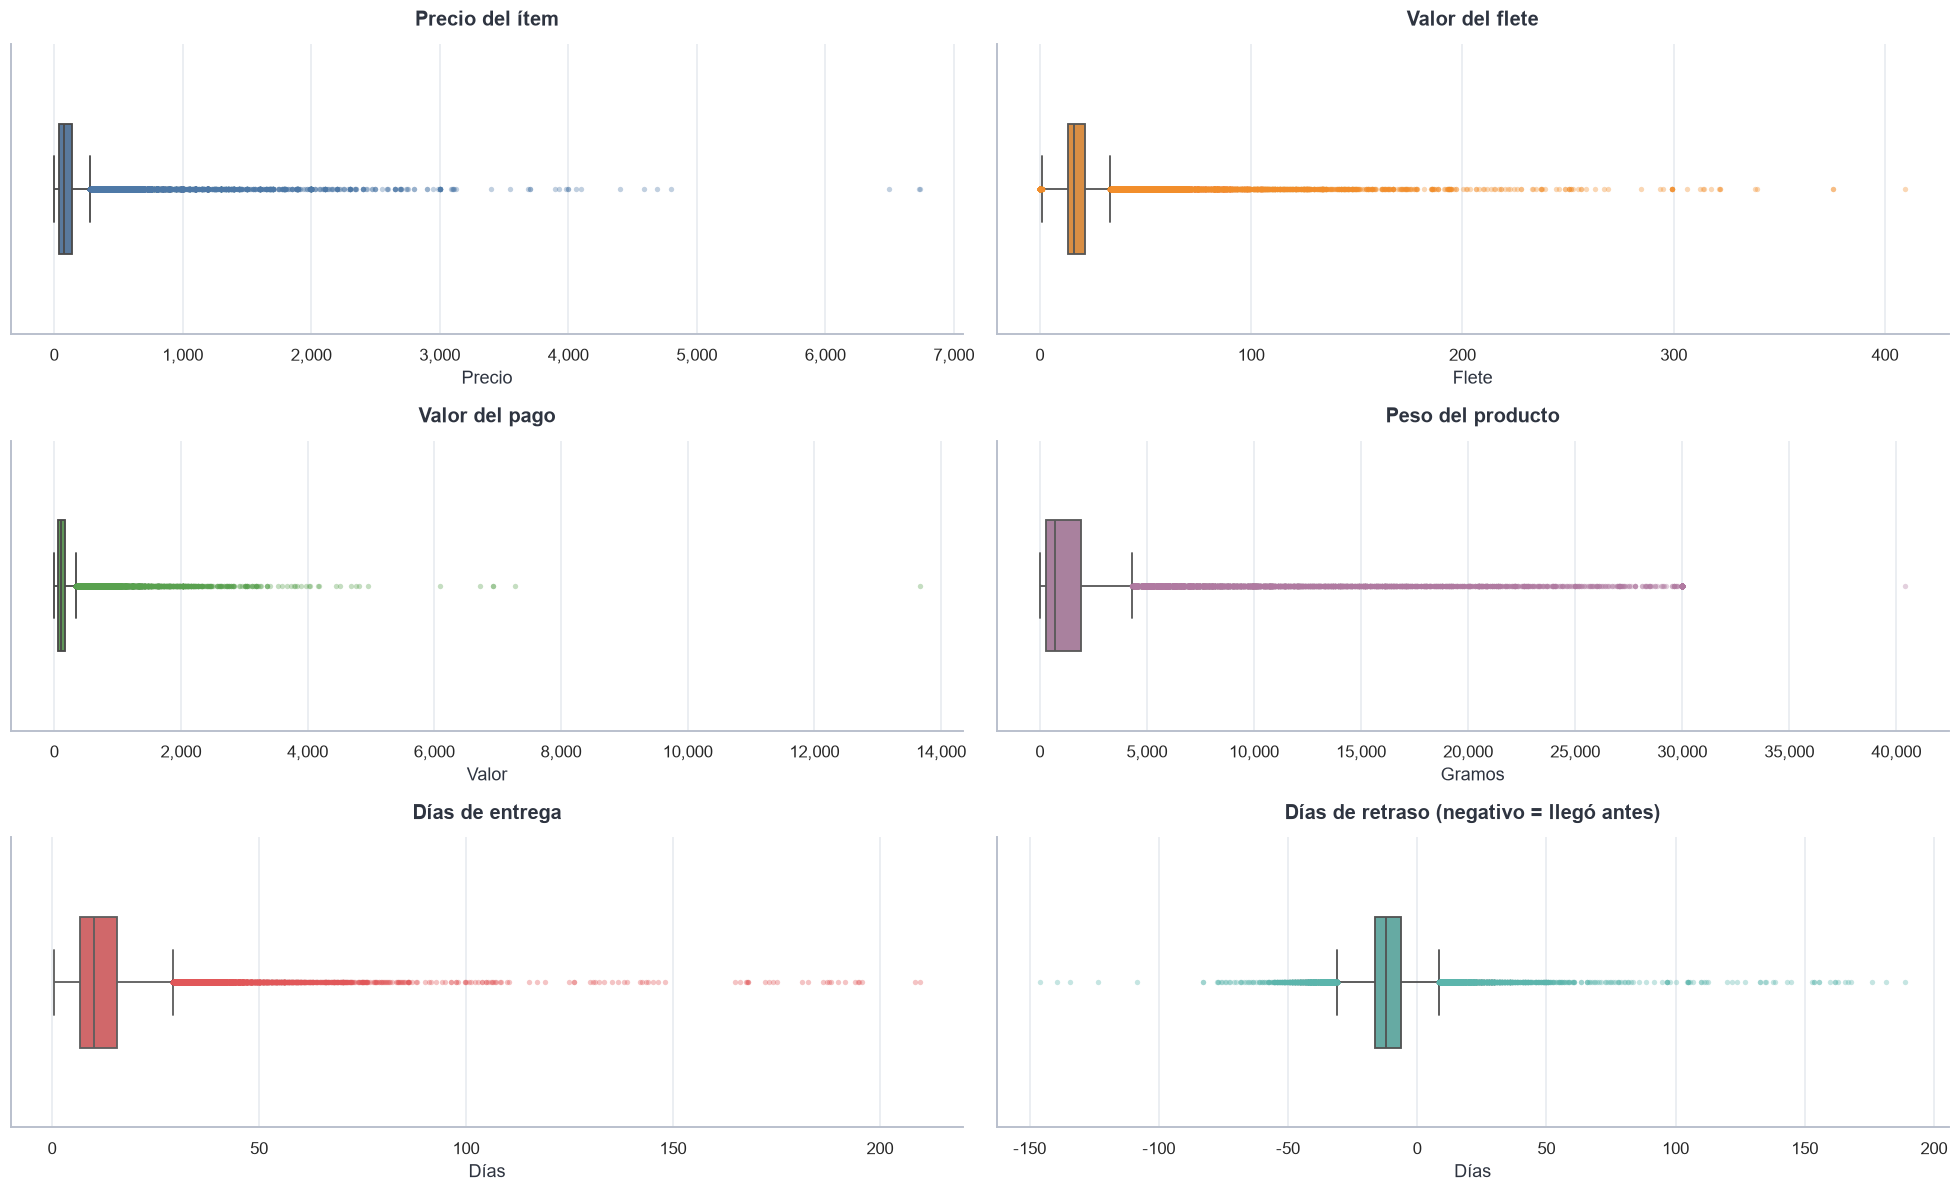

In [22]:
fig, ax = plt.subplots(3, 2, figsize=(18, 11))
caja(ax[0, 0], items["price"], AZUL, "Precio del ítem", "Precio")
caja(ax[0, 1], items["freight_value"], NARANJA, "Valor del flete", "Flete")
caja(ax[1, 0], payments["payment_value"], VERDE, "Valor del pago", "Valor")
caja(ax[1, 1], products["product_weight_g"], VIOLETA, "Peso del producto", "Gramos")
caja(ax[2, 0], entregados_ok["dias_entrega"], ROJO, "Días de entrega", "Días")
caja(ax[2, 1], entregados_ok["dias_retraso"], TURQUESA, "Días de retraso (negativo = llegó antes)", "Días")
plt.tight_layout()
plt.show()

### 7.2 Outliers en contexto
Precio extremo dentro de cada categoría, comparado con la regla global, y controles de reglas de negocio.

In [23]:
cat_item = items["product_id"].map(products.set_index("product_id")["categoria_producto"]).fillna("sin_categoria")
g = items.groupby(cat_item)["price"]
q1c = g.transform(lambda s: s.quantile(0.25))
q3c = g.transform(lambda s: s.quantile(0.75))
items["precio_outlier_categoria"] = items["price"] > q3c + 3 * (q3c - q1c)
items["precio_outlier"] = flag_outlier(items["price"])

display(pd.crosstab(items["precio_outlier"], items["precio_outlier_categoria"],
                    rownames=["extremo global"], colnames=["extremo en su categoría"]))

print("Los 10 precios más altos:")
display(items.assign(categoria=cat_item).nlargest(10, "price")[["order_id", "categoria", "price", "freight_value"]])

print(f"Ítems con flete mayor que el precio: {(items['freight_value'] > items['price']).mean() * 100:.1f}%")
print(f"Entregas de más de 100 días: {int((entregados_ok['dias_entrega'] > 100).sum())}")

extremo en su categoría,False,True
extremo global,,
False,107034,1542
True,1139,2935


Los 10 precios más altos:


,order_id,categoria,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,articulos_del_hogar,"6,735.00",194.31
112233,fefacc66af859508bf1a7934eab1e97f,computadoras,"6,729.00",193.21
107841,f5136e38d1a14a4dbd87dff67da82701,arte,"6,499.00",227.66
74336,a96610ab360d42a2e5335a3998b4718a,pequenos_electrodomesticos,"4,799.00",151.34
11249,199af31afc78c699f0dbf71fb178d4d4,pequenos_electrodomesticos,"4,690.00",74.34
62086,8dbc85d1447242f3b127dda390d56e19,computadoras,"4,590.00",91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,instrumentos_musicales,"4,399.87",113.45
45843,68101694e5c5dc7330c91e1bbc36214f,consolas_y_videojuegos,"4,099.99",75.27
78310,b239ca7cd485940b31882363b52e6674,deporte_y_ocio,"4,059.00",104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,relojes_y_regalos,"3,999.90",17.01


Ítems con flete mayor que el precio: 3.7%
Entregas de más de 100 días: 64


### 7.3 Impacto sobre las medidas de resumen

,media (todos),media (sin extremos),mediana,diferencia de la media (%)
price,120.65,94.04,74.99,28.30
freight_value,19.99,17.31,16.26,15.48
payment_value,154.10,121.93,100.00,26.38
product_weight_g,"2,276.75","1,117.85",700.00,103.67
dias_entrega,12.56,11.92,10.22,5.39


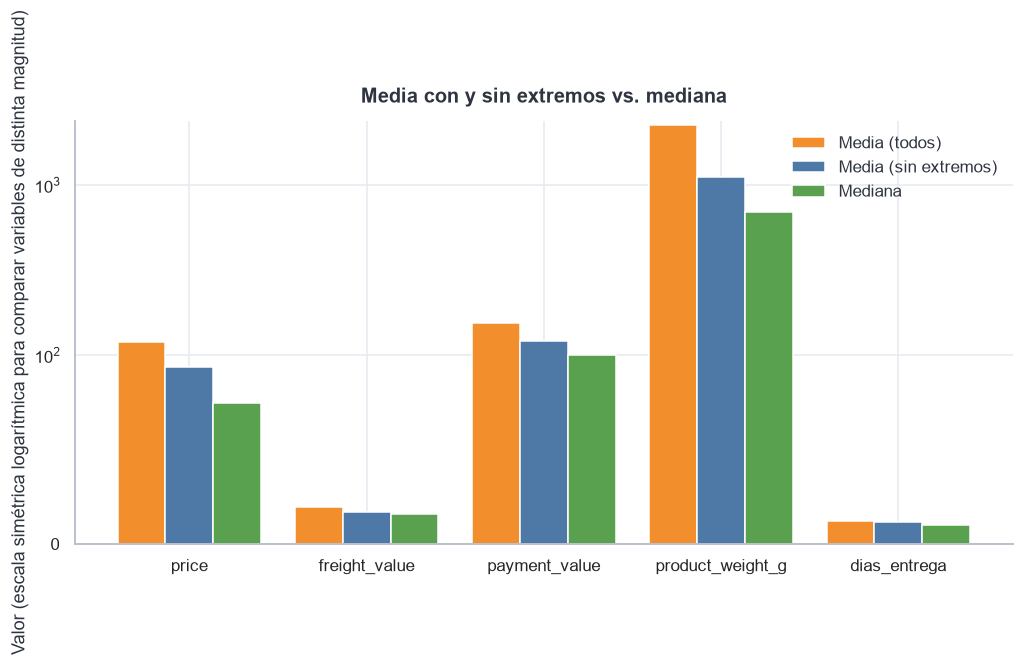

In [24]:
pares = {
    "price": items["price"], "freight_value": items["freight_value"], "payment_value": payments["payment_value"],
    "product_weight_g": products["product_weight_g"], "dias_entrega": entregados_ok["dias_entrega"],
}
impacto = pd.DataFrame({
    nombre: {
        "media (todos)": s.mean(),
        "media (sin extremos)": s[~flag_outlier(s)].mean(),
        "mediana": s.median(),
        "diferencia de la media (%)": (s.mean() / s[~flag_outlier(s)].mean() - 1) * 100,
    } for nombre, s in pares.items()
}).T
display(impacto)

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(impacto))
ancho = 0.27
ax.bar(x - ancho, impacto["media (todos)"], ancho, color=NARANJA, label="Media (todos)", edgecolor="white")
ax.bar(x, impacto["media (sin extremos)"], ancho, color=AZUL, label="Media (sin extremos)", edgecolor="white")
ax.bar(x + ancho, impacto["mediana"], ancho, color=VERDE, label="Mediana", edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(impacto.index)
ax.set_yscale("symlog", linthresh=100)
ax.set_title("Media con y sin extremos vs. mediana")
ax.set_ylabel("Valor (escala simétrica logarítmica para comparar variables de distinta magnitud)")
ax.legend(frameon=False)
plt.show()

### 7.4 Tratamiento
Los outliers se **marcan con banderas y se conservan**: corresponden a ventas y entregas reales. Los valores inválidos (peso ≤ 0, cuotas < 1) ya se corrigieron en la sección 5.

In [26]:
items["flete_outlier"] = flag_outlier(items["freight_value"])
payments["pago_outlier"] = flag_outlier(payments["payment_value"])
products["peso_outlier"] = flag_outlier(products["product_weight_g"])
orders["entrega_extrema"] = flag_outlier(orders["dias_entrega"].where(orders["order_status"] == "delivered"))

resumen_flags = pd.DataFrame({
    "tabla": ["items", "items", "items", "payments", "products", "orders"],
    "bandera": ["precio_outlier", "precio_outlier_categoria", "flete_outlier", "pago_outlier", "peso_outlier", "entrega_extrema"],
    "filas_marcadas": [int(items["precio_outlier"].sum()), int(items["precio_outlier_categoria"].sum()),
                       int(items["flete_outlier"].sum()), int(payments["pago_outlier"].sum()),
                       int(products["peso_outlier"].sum()), int(orders["entrega_extrema"].sum())],
})
display(resumen_flags)


,tabla,bandera,filas_marcadas
0,items,precio_outlier,4074
1,items,precio_outlier_categoria,4477
2,items,flete_outlier,5538
3,payments,pago_outlier,4046
4,products,peso_outlier,3073
5,orders,entrega_extrema,1370


## 8. Análisis univariado

Los histogramas usan la **escala original** de cada variable y se acotan al percentil 99 para que se aprecie el cuerpo de la distribución; los valores más extremos ya se analizaron en la sección 7. Las líneas indican la mediana y la media.

### 8.1 Clientes

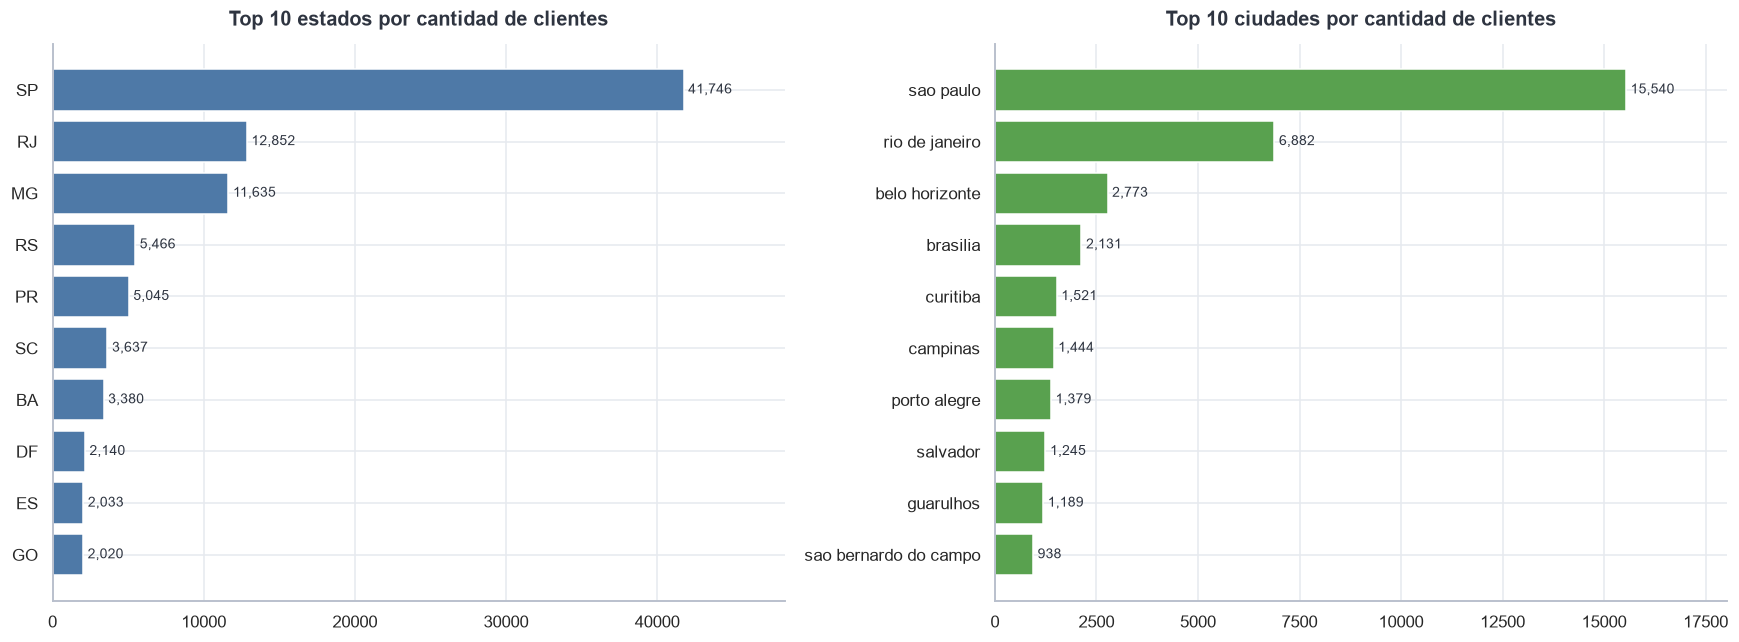

SP concentra 42.0% de los clientes; los 3 primeros estados, 66.6%.


In [27]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
barras(ax[0], customers["customer_state"].value_counts().head(10), AZUL, "Top 10 estados por cantidad de clientes", horizontal=True)
barras(ax[1], customers["customer_city"].value_counts().head(10), VERDE, "Top 10 ciudades por cantidad de clientes", horizontal=True)
plt.tight_layout()
plt.show()

share_estado = customers["customer_state"].value_counts(normalize=True)
print(f"{share_estado.index[0]} concentra {share_estado.iloc[0] * 100:.1f}% de los clientes; los 3 primeros estados, {share_estado.head(3).sum() * 100:.1f}%.")

### 8.2 Pedidos

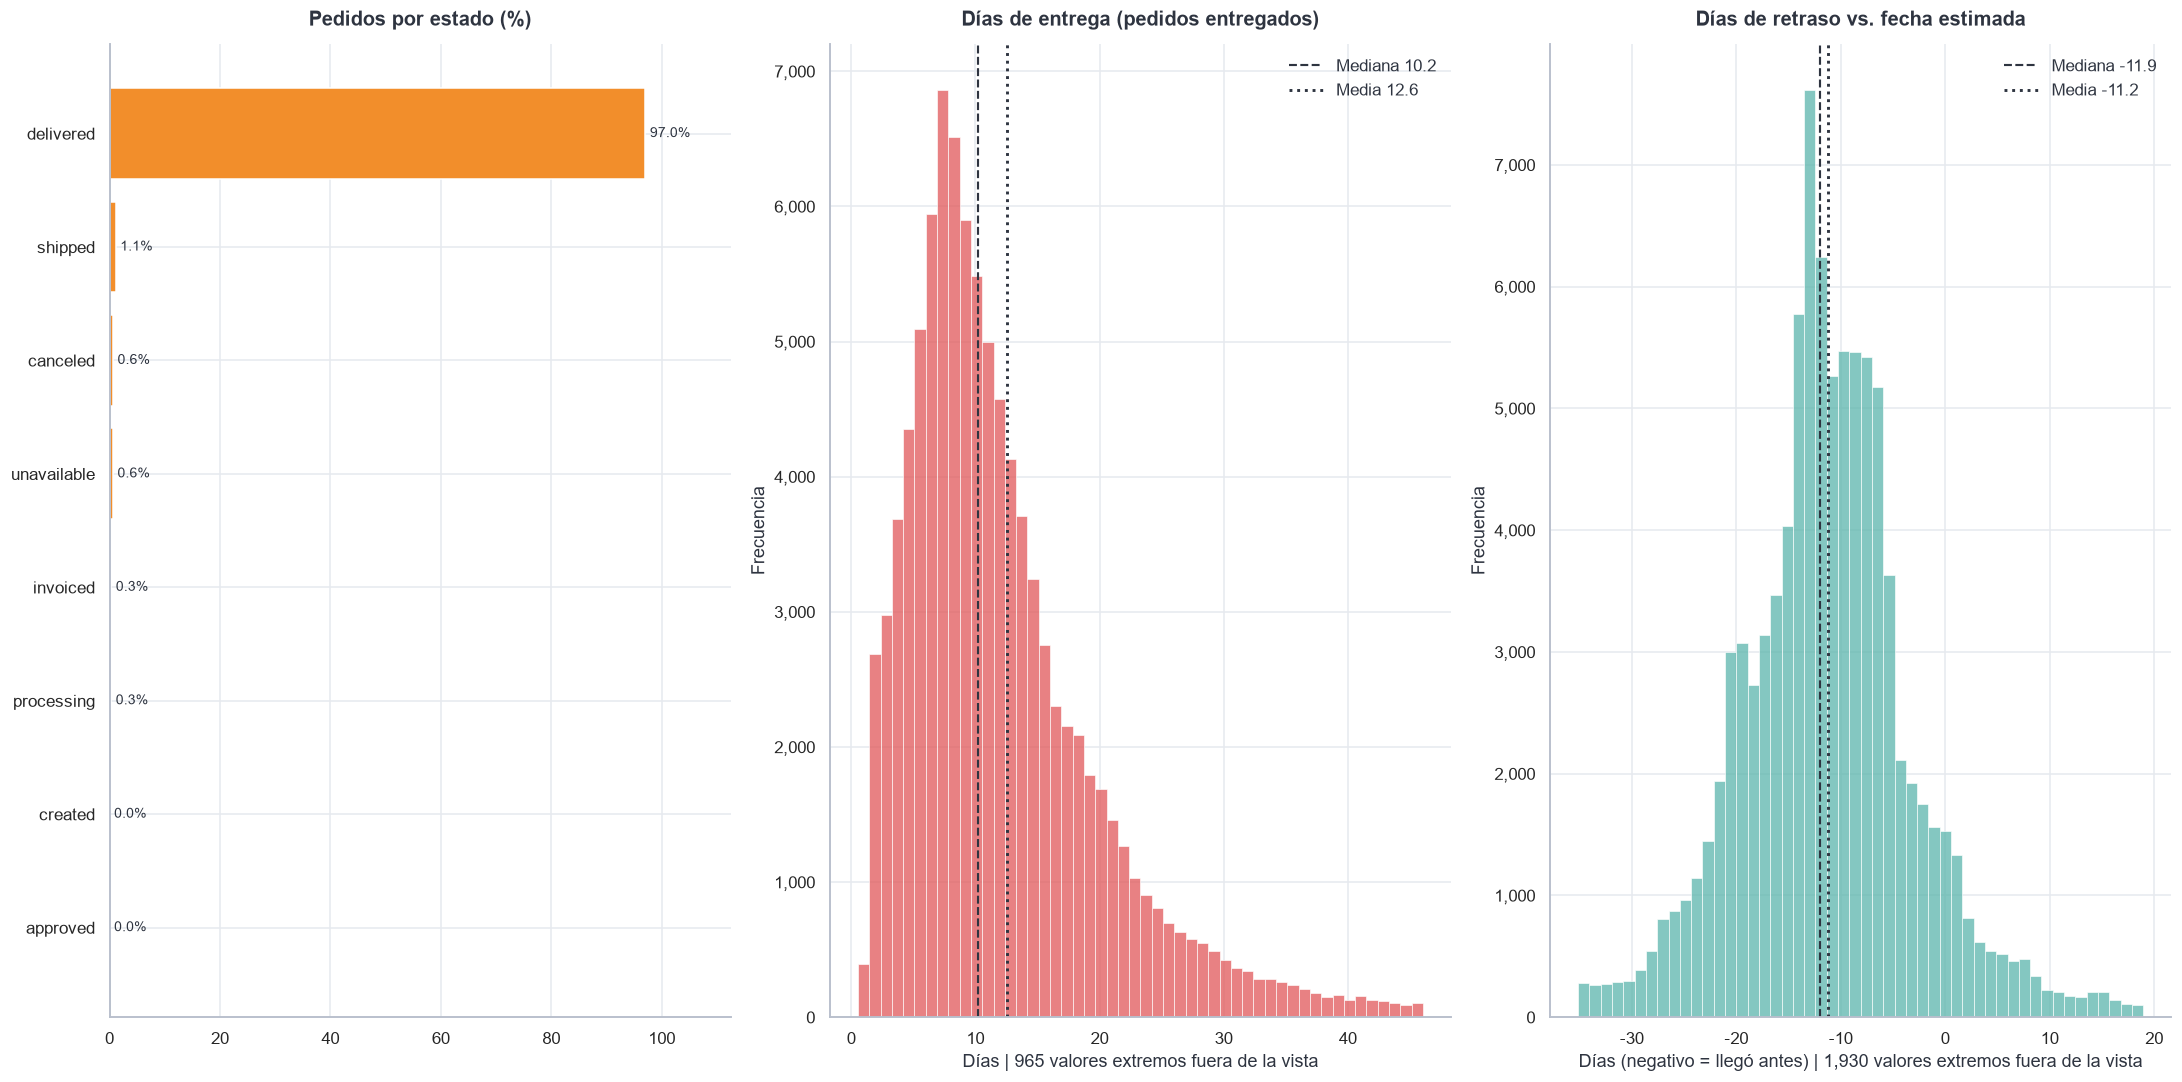

Rango de fechas de compra: 2016-09-04 21:15:19 -> 2018-10-17 17:30:18
Pedidos entregados: 97.0%


In [28]:
entregados_u = orders[orders["order_status"] == "delivered"]

fig, ax = plt.subplots(1, 3, figsize=(20, 10))
barras(ax[0], orders["order_status"].value_counts(normalize=True).mul(100), NARANJA, "Pedidos por estado (%)", horizontal=True, fmt="{:.1f}%")
hist_nominal(ax[1], entregados_u["dias_entrega"], ROJO, "Días de entrega (pedidos entregados)", "Días")
hist_nominal(ax[2], entregados_u["dias_retraso"], TURQUESA, "Días de retraso vs. fecha estimada", "Días (negativo = llegó antes)", dos_colas=True)
plt.tight_layout()
plt.show()

print("Rango de fechas de compra:", orders["order_purchase_timestamp"].min(), "->", orders["order_purchase_timestamp"].max())
print(f"Pedidos entregados: {(orders['order_status'] == 'delivered').mean() * 100:.1f}%")

### 8.3 Ítems

,count,mean,std,min,1%,25%,50%,75%,99%,max,asimetría
price,"112,650.00",120.65,183.63,0.85,9.99,39.90,74.99,134.90,890.00,"6,735.00",7.92
freight_value,"112,650.00",19.99,15.81,0.00,4.42,13.08,16.26,21.15,84.52,409.68,5.64
valor_total_item,"112,650.00",140.64,190.72,6.08,20.86,55.22,92.32,157.94,923.22,"6,929.31",7.69


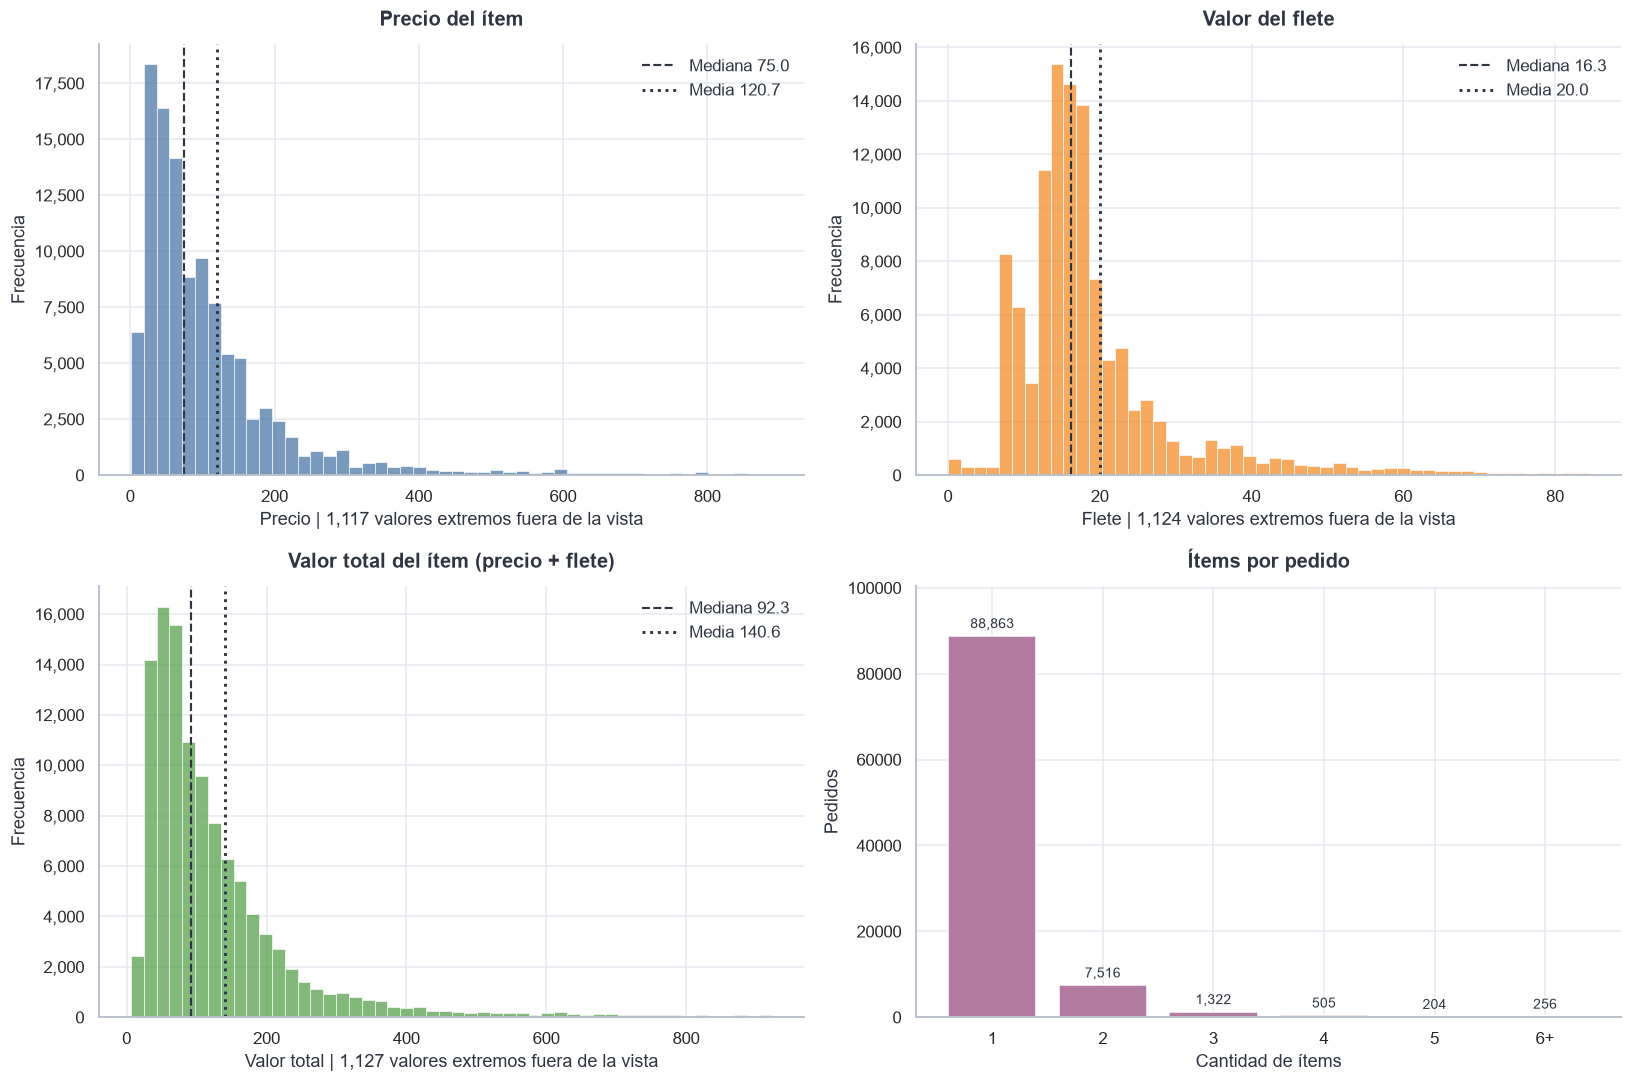

Precio mediano: 74.99 | media: 120.65
Pedidos con un solo ítem: 90.1%


In [29]:
display(resumen_numerico(items, ["price", "freight_value", "valor_total_item"]))

fig, ax = plt.subplots(2, 2, figsize=(15, 10))
hist_nominal(ax[0, 0], items["price"], AZUL, "Precio del ítem", "Precio")
hist_nominal(ax[0, 1], items["freight_value"], NARANJA, "Valor del flete", "Flete")
hist_nominal(ax[1, 0], items["valor_total_item"], VERDE, "Valor total del ítem (precio + flete)", "Valor total")
items_por_pedido = items.groupby("order_id").size()
barras(ax[1, 1], items_por_pedido.clip(upper=6).value_counts().sort_index().rename(lambda i: f"{i}+" if i == 6 else str(i)),
       VIOLETA, "Ítems por pedido", xlabel="Cantidad de ítems", ylabel="Pedidos")
plt.tight_layout()
plt.show()

print(f"Precio mediano: {items['price'].median():,.2f} | media: {items['price'].mean():,.2f}")
print(f"Pedidos con un solo ítem: {(items_por_pedido == 1).mean() * 100:.1f}%")

### 8.4 Pagos

,count,mean,std,min,1%,25%,50%,75%,99%,max,asimetría
payment_value,"103,886.00",154.10,217.49,0.00,6.69,56.79,100.00,171.84,"1,039.92","13,664.08",9.25
payment_installments,"103,886.00",2.85,2.69,1.00,1.00,1.00,1.00,4.00,10.00,24.00,1.66


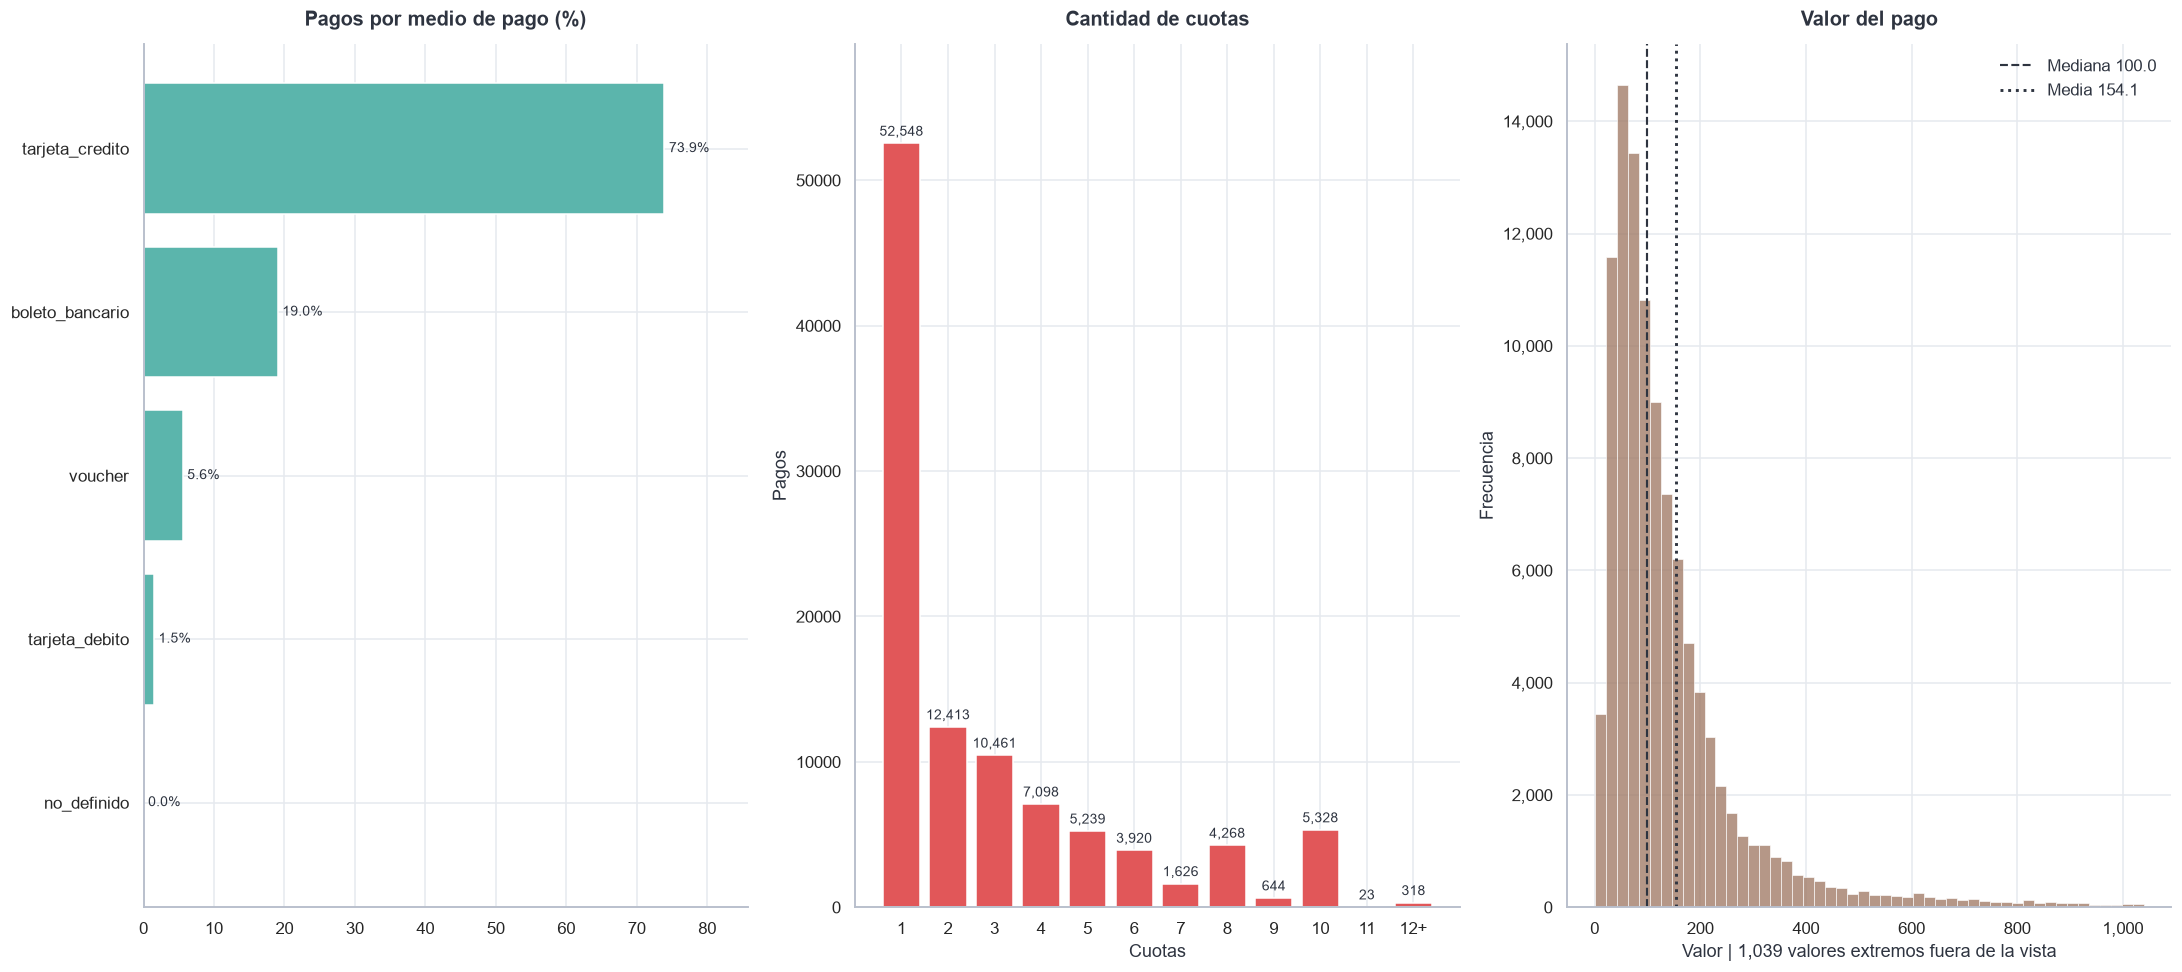

Medio de pago más usado: tarjeta_credito (73.9% de los pagos)


In [30]:
display(resumen_numerico(payments, ["payment_value", "payment_installments"]))

cuotas = payments["payment_installments"].clip(upper=12).value_counts().sort_index()
cuotas.index = [f"{i}+" if i == 12 else str(i) for i in cuotas.index]

fig, ax = plt.subplots(1, 3, figsize=(20, 9))
barras(ax[0], payments["tipo_pago"].value_counts(normalize=True).mul(100), TURQUESA, "Pagos por medio de pago (%)", horizontal=True, fmt="{:.1f}%")
barras(ax[1], cuotas, ROJO, "Cantidad de cuotas", xlabel="Cuotas", ylabel="Pagos")
hist_nominal(ax[2], payments["payment_value"], MARRON, "Valor del pago", "Valor")
plt.tight_layout()
plt.show()

top_pago = payments["tipo_pago"].value_counts(normalize=True)
print(f"Medio de pago más usado: {top_pago.index[0]} ({top_pago.iloc[0] * 100:.1f}% de los pagos)")

### 8.5 Productos

,count,mean,std,min,1%,25%,50%,75%,99%,max,asimetría
product_weight_g,"32,945.00","2,276.75","4,282.23",2.00,61.88,300.00,700.00,"1,900.00","22,539.00","40,425.00",3.60
product_volume_cm3,"32,949.00","16,564.10","27,057.04",168.00,352.00,"2,880.00","6,840.00","18,480.00","135,917.44","296,208.00",4.18
product_photos_qty,"32,341.00",2.19,1.74,1.00,1.00,1.00,1.00,3.00,8.00,20.00,2.19
product_name_length,"32,341.00",48.48,10.25,5.00,20.00,42.00,51.00,57.00,63.00,76.00,-0.90
product_description_length,"32,341.00",771.50,635.12,4.00,84.00,339.00,595.00,972.00,"3,286.20","3,992.00",1.96


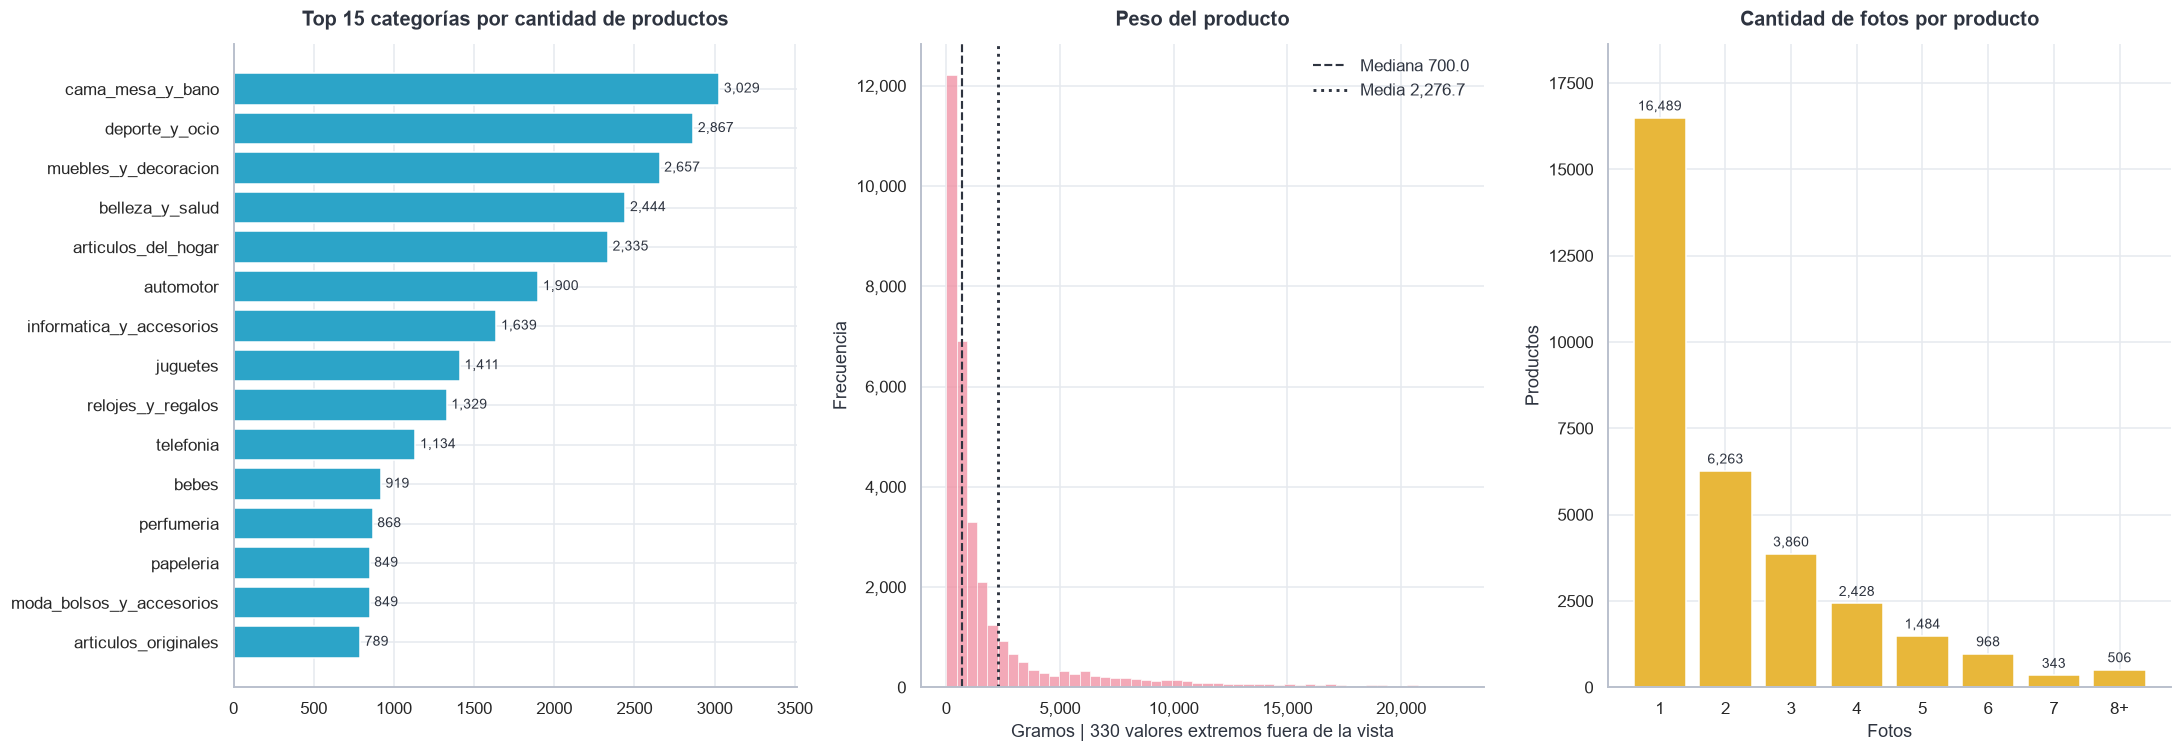

Categorías distintas: 74


In [31]:
display(resumen_numerico(products, ["product_weight_g", "product_volume_cm3", "product_photos_qty",
                                    "product_name_length", "product_description_length"]))

fotos = products["product_photos_qty"].dropna().clip(upper=8).astype(int).value_counts().sort_index()
fotos.index = [f"{i}+" if i == 8 else str(i) for i in fotos.index]

fig, ax = plt.subplots(1, 3, figsize=(20, 7))
barras(ax[0], products["categoria_producto"].value_counts().head(15), CIAN, "Top 15 categorías por cantidad de productos", horizontal=True)
hist_nominal(ax[1], products["product_weight_g"], ROSA, "Peso del producto", "Gramos")
barras(ax[2], fotos, ORO, "Cantidad de fotos por producto", xlabel="Fotos", ylabel="Productos")
plt.tight_layout()
plt.show()

print(f"Categorías distintas: {products['categoria_producto'].nunique()}")

### 8.6 Reseñas

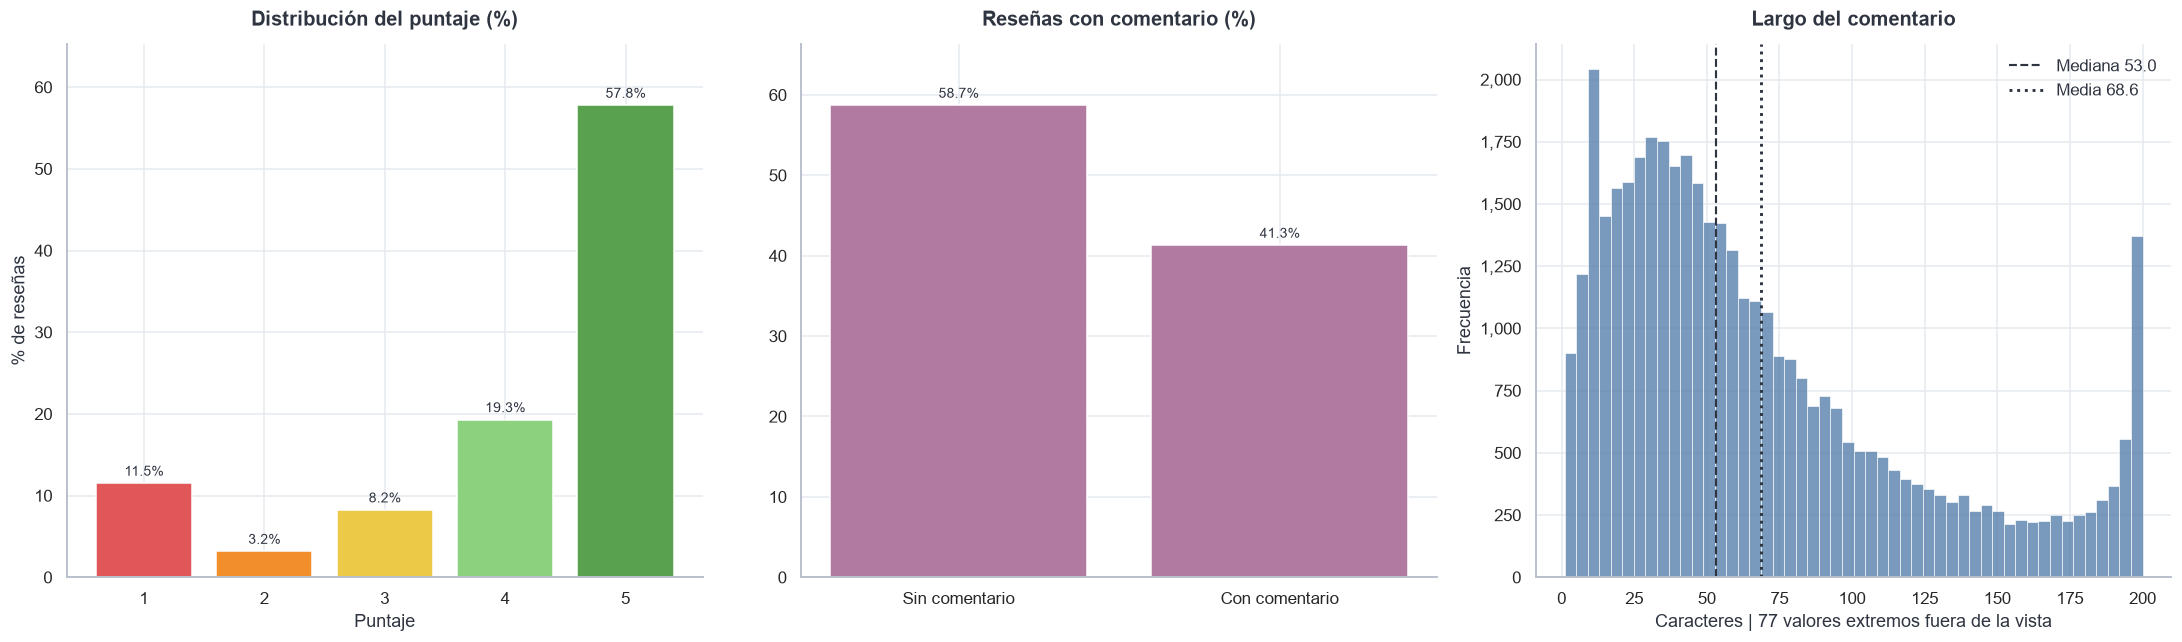

Puntaje promedio: 4.09
Reseñas de 5 estrellas: 57.8% | de 1 a 2 estrellas: 14.7%


In [32]:
puntajes = reviews["review_score"].value_counts(normalize=True).sort_index().mul(100)
comentario = reviews["tiene_comentario"].map({0: "Sin comentario", 1: "Con comentario"}).value_counts(normalize=True).mul(100)

fig, ax = plt.subplots(1, 3, figsize=(20, 6))
barras(ax[0], puntajes, ESCALA_PUNTAJE, "Distribución del puntaje (%)", fmt="{:.1f}%", xlabel="Puntaje", ylabel="% de reseñas")
barras(ax[1], comentario, VIOLETA, "Reseñas con comentario (%)", fmt="{:.1f}%")
hist_nominal(ax[2], reviews.loc[reviews["largo_comentario"] > 0, "largo_comentario"], AZUL, "Largo del comentario", "Caracteres")
plt.tight_layout()
plt.show()

print(f"Puntaje promedio: {reviews['review_score'].mean():.2f}")
print(f"Reseñas de 5 estrellas: {(reviews['review_score'] == 5).mean() * 100:.1f}% | de 1 a 2 estrellas: {(reviews['review_score'] <= 2).mean() * 100:.1f}%")

## 9. Tablas consolidadas

Se construyen dos tablas con granularidad distinta:
- **`master`**: una fila por pedido (ingresos, logística, satisfacción, clientes).
- **`items_full`**: una fila por ítem (categorías y vendedores).

Los ítems, pagos y reseñas se agregan a nivel pedido **antes** de unir, y cada `merge` usa `validate` para evitar la multiplicación de filas.

### 9.1 Agregaciones por pedido

In [34]:
items_orden = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    n_productos=("product_id", "nunique"),
    n_vendedores=("seller_id", "nunique"),
    valor_productos=("price", "sum"),
    valor_flete=("freight_value", "sum"),
).reset_index()
items_orden["pct_flete"] = items_orden["valor_flete"] / items_orden["valor_productos"] * 100

pagos = payments.assign(es_voucher=payments["payment_type"].eq("voucher"))
pagos_orden = pagos.groupby("order_id").agg(
    n_pagos=("payment_sequential", "count"),
    valor_pagado=("payment_value", "sum"),
    cuotas_max=("payment_installments", "max"),
    usa_voucher=("es_voucher", "max"),
).reset_index()

principal = (
    payments.sort_values(["order_id", "payment_value"], ascending=[True, False])
    .drop_duplicates("order_id")[["order_id", "payment_type", "tipo_pago"]]
    .rename(columns={"payment_type": "payment_type_principal", "tipo_pago": "tipo_pago_principal"})
)
pagos_orden = pagos_orden.merge(principal, on="order_id", how="left", validate="1:1")

reviews_orden = (
    reviews.sort_values("review_answer_timestamp").groupby("order_id")
    .agg(review_score=("review_score", "last"), insatisfecho=("insatisfecho", "last"),
         tiene_comentario=("tiene_comentario", "max"), n_reviews=("review_id", "count"))
    .reset_index()
)

for nombre, t in {"items_orden": items_orden, "pagos_orden": pagos_orden, "reviews_orden": reviews_orden}.items():
    assert t["order_id"].is_unique, f"{nombre} no es único por pedido"
    print(f"{nombre:<14} {len(t):>8,} filas (1 por pedido)")



items_orden      98,666 filas (1 por pedido)
pagos_orden      99,440 filas (1 por pedido)
reviews_orden    98,673 filas (1 por pedido)


### 9.2 Tabla `master`

In [56]:
master = (
    orders
    .merge(customers, on="customer_id", how="left", validate="m:1")
    .merge(items_orden, on="order_id", how="left", validate="1:1")
    .merge(pagos_orden, on="order_id", how="left", validate="1:1")
    .merge(reviews_orden, on="order_id", how="left", validate="1:1")
)

assert len(master) == len(orders)
assert master["order_id"].is_unique

master["ticket"] = master["valor_productos"] + master["valor_flete"]
dif = (master["valor_pagado"] - master["ticket"]).abs()
con_ambos = master["ticket"].notna() & master["valor_pagado"].notna()

print(f"master: {master.shape[0]:,} filas x {master.shape[1]} columnas (igual a orders)")
print(f"Suma de price en items          : {items['price'].sum():>15,.2f}")
print(f"Suma de valor_productos (master): {master['valor_productos'].sum():>15,.2f}")
print(f"Pedidos con diferencia > 1 entre ticket y valor pagado: {(dif[con_ambos] > 1).mean() * 100:.2f}%")


master: 99,441 filas x 41 columnas (igual a orders)
Suma de price en items          :   13,591,643.70
Suma de valor_productos (master):   13,591,643.70
Pedidos con diferencia > 1 entre ticket y valor pagado: 0.25%


### 9.3 Ventas válidas
Se excluyen los pedidos `canceled` y `unavailable` de los ingresos. El análisis de logística usa solo pedidos `delivered`.

In [37]:
ESTADOS_EXCLUIDOS = ["canceled", "unavailable"]
master_v = master[~master["order_status"].isin(ESTADOS_EXCLUIDOS)].copy()
entregados = master_v[master_v["order_status"] == "delivered"].copy()

print(f"Pedidos totales    : {len(master):,}")
print(f"Ventas válidas     : {len(master_v):,} ({len(master_v) / len(master) * 100:.1f}%)")
print(f"Pedidos entregados : {len(entregados):,}")


Pedidos totales    : 99,441
Ventas válidas     : 98,207 (98.8%)
Pedidos entregados : 96,478


### 9.4 Tabla `items_full`

In [39]:
items_full = (
    items
    .merge(products, on="product_id", how="left", validate="m:1")
    .merge(orders[["order_id", "customer_id", "order_status", "mes_compra"]], on="order_id", how="left", validate="m:1")
    .merge(customers[["customer_id", "customer_state", "customer_region"]], on="customer_id", how="left", validate="m:1")
    .merge(reviews_orden[["order_id", "review_score"]], on="order_id", how="left", validate="m:1")
)

assert len(items_full) == len(items)
items_full_v = items_full[~items_full["order_status"].isin(ESTADOS_EXCLUIDOS)].copy()
print(f"items_full: {items_full.shape[0]:,} filas x {items_full.shape[1]} columnas (igual a items)")


items_full: 112,650 filas x 29 columnas (igual a items)


## 10. Análisis bivariado y multivariado

Esta sección calcula las tablas de análisis que sustentan las respuestas de la sección 11, donde se presentan los gráficos correspondientes.

### 10.1 Evolución mensual
Las series de tiempo usan únicamente **meses completos**: los primeros meses (plataforma en lanzamiento) y los últimos (datos parciales) se excluyen de las tendencias, pero no del resto del análisis. Ajustar `MES_INI` y `MES_FIN` según el volumen mensual observado.

In [41]:
MES_INI = pd.Timestamp("2017-01-01")
MES_FIN = pd.Timestamp("2018-08-01")

mensual_total = (
    master_v.groupby("mes_compra")
    .agg(pedidos=("order_id", "count"), ingresos=("valor_productos", "sum"), ticket_medio=("valor_productos", "mean"))
    .reset_index()
)
mensual_total["en_ventana"] = mensual_total["mes_compra"].between(MES_INI, MES_FIN)
mensual = mensual_total[mensual_total["en_ventana"]].reset_index(drop=True)
display(mensual_total)

fuera_ventana = int(master_v.loc[~master_v["mes_compra"].between(MES_INI, MES_FIN)].shape[0])
crec_total = (mensual["pedidos"].iloc[-1] / mensual["pedidos"].iloc[0] - 1) * 100
print(f"Ventana: {MES_INI:%Y-%m} a {MES_FIN:%Y-%m}. Pedidos fuera de la ventana: {fuera_ventana:,}")
print(f"Variación de pedidos entre el primer y el último mes de la ventana: {crec_total:,.0f}%")

,mes_compra,pedidos,ingresos,ticket_medio,en_ventana
0,2016-09-01,2,207.86,103.93,False
1,2016-10-01,293,"44,507.30",153.47,False
2,2016-12-01,1,10.90,10.90,False
3,2017-01-01,787,"120,098.27",152.60,True
4,2017-02-01,1718,"244,959.35",142.58,True
5,2017-03-01,2617,"368,341.32",140.75,True
6,2017-04-01,2377,"353,842.98",148.86,True
7,2017-05-01,3640,"503,159.19",138.23,True
8,2017-06-01,3205,"429,916.61",134.14,True
9,2017-07-01,3946,"492,287.30",124.76,True


Ventana: 2017-01 a 2018-08. Pedidos fuera de la ventana: 297
Variación de pedidos entre el primer y el último mes de la ventana: 716%


### 10.2 Estacionalidad semanal y horaria

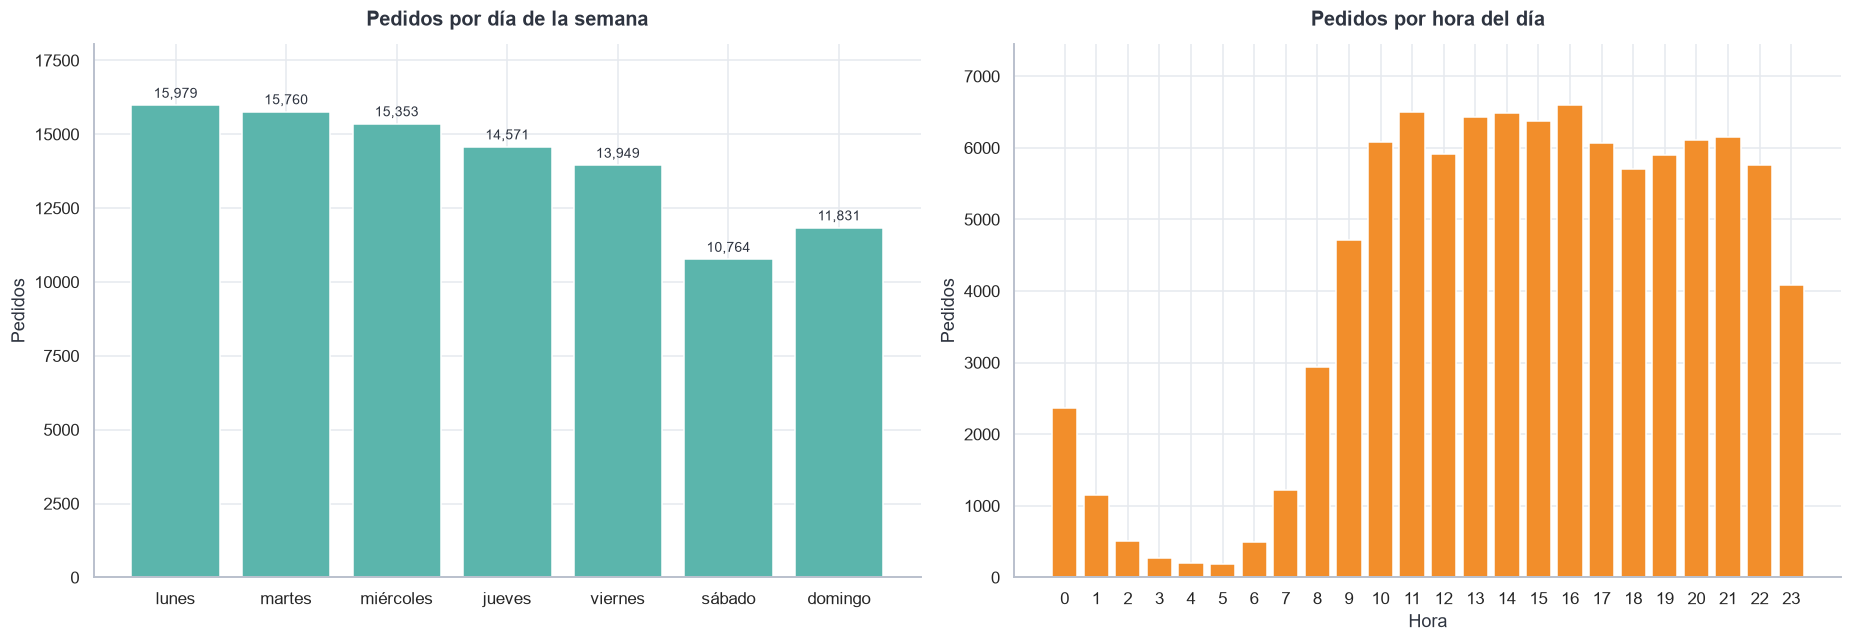

In [42]:
DIAS_ES = {"Monday": "lunes", "Tuesday": "martes", "Wednesday": "miércoles", "Thursday": "jueves",
           "Friday": "viernes", "Saturday": "sábado", "Sunday": "domingo"}

por_dia = master_v["dia_semana"].value_counts().reindex(list(DIAS_ES)).rename(index=DIAS_ES)
por_hora = master_v["hora_compra"].value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
barras(ax[0], por_dia, TURQUESA, "Pedidos por día de la semana", ylabel="Pedidos")
barras(ax[1], por_hora, NARANJA, "Pedidos por hora del día", xlabel="Hora", ylabel="Pedidos", valores=False)
plt.tight_layout()
plt.show()

### 10.3 Geografía

In [43]:
geo = (
    master_v.groupby("customer_state")
    .agg(pedidos=("order_id", "count"), ingresos=("valor_productos", "sum"),
         ticket_medio=("valor_productos", "mean"), flete_medio=("valor_flete", "mean"),
         dias_entrega=("dias_entrega", "mean"), pct_tarde=("entregado_tarde", "mean"),
         score_medio=("review_score", "mean"))
    .sort_values("ingresos", ascending=False)
)
geo["pct_tarde"] = geo["pct_tarde"] * 100
geo["% ingresos"] = geo["ingresos"] / geo["ingresos"].sum() * 100
display(geo.head(10))

region = (
    master_v.groupby("customer_region")
    .agg(pedidos=("order_id", "count"), ingresos=("valor_productos", "sum"), flete_medio=("valor_flete", "mean"),
         dias_entrega=("dias_entrega", "mean"), score_medio=("review_score", "mean"))
    .sort_values("ingresos", ascending=False)
)
region["% ingresos"] = region["ingresos"] / region["ingresos"].sum() * 100
display(region)

,pedidos,ingresos,ticket_medio,flete_medio,dias_entrega,pct_tarde,score_medio,% ingresos
customer_state,,,,,,,,
SP,41127,"5,163,867.22",125.57,17.37,8.76,5.89,4.21,38.27
RJ,12698,"1,811,623.42",142.68,23.95,15.31,13.47,3.90,13.43
MG,11496,"1,573,508.20",136.87,23.45,12.01,5.61,4.16,11.66
RS,5417,"742,559.78",137.13,24.88,15.30,7.15,4.15,5.50
PR,4983,"676,883.06",135.87,23.55,11.99,5.00,4.21,5.02
SC,3600,"518,578.28",144.09,24.85,14.95,9.76,4.10,3.84
BA,3344,"507,108.83",151.65,29.84,19.34,14.04,3.88,3.76
DF,2121,"300,886.45",141.93,23.79,12.97,7.07,4.09,2.23
GO,1998,"287,870.46",144.08,26.36,15.61,8.18,4.07,2.13


,pedidos,ingresos,flete_medio,dias_entrega,score_medio,% ingresos
customer_region,,,,,,
Sudeste,67339,"8,822,530.97",19.86,10.75,4.14,65.38
Sur,14000,"1,938,021.12",24.40,14.03,4.16,14.36
Nordeste,9305,"1,538,209.28",35.93,20.01,3.92,11.40
Centro-Oeste,5729,"861,825.09",26.52,15.02,4.09,6.39
Norte,1834,"333,814.28",41.39,22.59,3.98,2.47


### 10.4 Categorías
Se usa `items_full` (nivel ítem) para repartir correctamente el valor entre categorías.

In [44]:
cat = (
    items_full_v.groupby("categoria_producto")
    .agg(unidades=("order_item_id", "count"), ingresos=("price", "sum"), precio_medio=("price", "mean"),
         flete_medio=("freight_value", "mean"), score_medio=("review_score", "mean"))
    .sort_values("ingresos", ascending=False)
)
cat["% ingresos"] = cat["ingresos"] / cat["ingresos"].sum() * 100
cat["% acumulado"] = cat["% ingresos"].cumsum()
display(cat.head(15))

n80 = int((cat["% acumulado"] <= 80).sum() + 1)
print(f"{n80} de {len(cat)} categorías explican el 80% de los ingresos.")

,unidades,ingresos,precio_medio,flete_medio,score_medio,% ingresos,% acumulado
categoria_producto,,,,,,,
belleza_y_salud,9634,"1,255,695.13",130.34,18.89,4.15,9.31,9.31
relojes_y_regalos,5970,"1,198,185.21",200.70,16.77,4.03,8.88,18.18
cama_mesa_y_bano,11097,"1,035,964.06",93.36,18.42,3.90,7.68,25.86
deporte_y_ocio,8590,"979,740.92",114.06,19.50,4.12,7.26,33.12
informatica_y_accesorios,7781,"904,322.02",116.22,18.84,3.95,6.70,39.82
muebles_y_decoracion,8298,"727,465.05",87.67,20.75,3.92,5.39,45.21
articulos_del_hogar,6915,"626,825.80",90.65,21.00,4.07,4.65,49.86
articulos_originales,3779,"620,770.49",164.27,22.05,4.16,4.60,54.46
automotor,4204,"586,585.73",139.53,21.89,4.08,4.35,58.81


18 de 74 categorías explican el 80% de los ingresos.


### 10.5 Vendedores

In [57]:
vend = items_full_v.groupby("seller_id")["price"].sum().sort_values(ascending=False)
acum = vend.cumsum() / vend.sum() * 100
share_top10 = vend.head(int(len(vend) * 0.10)).sum() / vend.sum() * 100

display(vend.head(10).rename("ingresos").to_frame())
print(f"Vendedores activos: {len(vend):,}. El 10% de los vendedores concentra {share_top10:.1f}% de los ingresos.")

,ingresos
seller_id,
4869f7a5dfa277a7dca6462dcf3b52b2,"229,237.63"
53243585a1d6dc2643021fd1853d8905,"222,776.05"
4a3ca9315b744ce9f8e9374361493884,"200,326.12"
fa1c13f2614d7b5c4749cbc52fecda94,"192,842.13"
7c67e1448b00f6e969d365cea6b010ab,"187,923.89"
7e93a43ef30c4f03f38b393420bc753a,"172,583.88"
da8622b14eb17ae2831f4ac5b9dab84a,"160,236.57"
7a67c85e85bb2ce8582c35f2203ad736,"141,715.54"
1025f0e2d44d7041d6cf58b6550e0bfa,"138,968.55"


Vendedores activos: 3,053. El 10% de los vendedores concentra 67.4% de los ingresos.


### 10.6 Medios de pago y cuotas
Se usa el medio de pago principal de cada pedido.

In [45]:
pagos_res = (
    master_v.dropna(subset=["tipo_pago_principal"]).groupby("tipo_pago_principal")
    .agg(pedidos=("order_id", "count"), ticket_medio=("valor_pagado", "mean"), cuotas_medias=("cuotas_max", "mean"))
    .sort_values("pedidos", ascending=False)
)
pagos_res["% pedidos"] = pagos_res["pedidos"] / pagos_res["pedidos"].sum() * 100
display(pagos_res)

tarjeta = master_v[master_v["payment_type_principal"] == "credit_card"].copy()
tarjeta["tramo_cuotas"] = pd.cut(tarjeta["cuotas_max"], bins=[0, 1, 3, 6, 10, 100],
                                 labels=["1", "2-3", "4-6", "7-10", "11+"])
med_cuotas = tarjeta.groupby("tramo_cuotas", observed=True)["valor_pagado"].median()
display(med_cuotas.rename("mediana del valor pagado").to_frame())

,pedidos,ticket_medio,cuotas_medias,% pedidos
tipo_pago_principal,,,,
tarjeta_credito,74116,166.64,3.55,75.47
boleto_bancario,19539,144.67,1.00,19.90
voucher,3037,114.94,1.15,3.09
tarjeta_debito,1514,140.27,1.00,1.54


,mediana del valor pagado
tramo_cuotas,
1,71.63
2-3,111.43
4-6,128.19
7-10,206.49
11+,217.10


### 10.7 Logística
Pedidos entregados, con fechas consistentes.

In [46]:
ent_ok = entregados[entregados["dias_entrega"].notna() & ~entregados["fecha_inconsistente"].fillna(False)]
print(f"Pedidos analizados: {len(ent_ok):,}")
display(ent_ok[["dias_entrega", "dias_estimados", "dias_retraso"]].describe(percentiles=[.05, .5, .95]).T)

tarde_mes = (ent_ok[ent_ok["mes_compra"].between(MES_INI, MES_FIN)]
             .groupby("mes_compra")["entregado_tarde"].mean().mul(100))
print(f"Mediana de entrega: {ent_ok['dias_entrega'].median():.1f} días")
print(f"Entregados después de la fecha estimada: {ent_ok['entregado_tarde'].mean() * 100:.1f}%")

Pedidos analizados: 95,097


,count,mean,std,min,5%,50%,95%,max
dias_entrega,"95,097.00",12.62,9.57,0.53,3.04,10.27,29.40,209.63
dias_estimados,"95,097.00",23.75,8.77,2.01,10.48,23.24,38.42,155.14
dias_retraso,"95,097.00",-11.13,10.20,-146.02,-25.61,-11.59,3.88,188.98


Mediana de entrega: 10.3 días
Entregados después de la fecha estimada: 8.2%


### 10.8 Satisfacción

In [47]:
ent_rev = ent_ok.dropna(subset=["review_score"]).copy()
ent_rev["tramo_retraso"] = pd.cut(
    ent_rev["dias_retraso"], bins=[-np.inf, 0, 3, 7, np.inf],
    labels=["A tiempo o antes", "1-3 días tarde", "4-7 días tarde", "Más de 7 días tarde"],
)
tabla_retraso = (
    ent_rev.groupby("tramo_retraso", observed=True)
    .agg(pedidos=("order_id", "count"), puntaje_medio=("review_score", "mean"), pct_insatisfechos=("insatisfecho", "mean"))
)
tabla_retraso["pct_insatisfechos"] = tabla_retraso["pct_insatisfechos"] * 100
display(tabla_retraso)

ent_rev["tramo_entrega"] = pd.cut(ent_rev["dias_entrega"], bins=[0, 7, 14, 21, 30, np.inf],
                                  labels=["≤7", "8-14", "15-21", "22-30", ">30"])
puntaje_por_entrega = ent_rev.groupby("tramo_entrega", observed=True)["review_score"].mean()
display(puntaje_por_entrega.rename("puntaje medio").to_frame())

MIN_UNIDADES = 300
cat_score = cat[cat["unidades"] >= MIN_UNIDADES].sort_values("score_medio")
print(f"Categorías con al menos {MIN_UNIDADES} unidades: {len(cat_score)} de {len(cat)}. Menor y mayor puntaje medio:")
display(pd.concat([cat_score.head(5), cat_score.tail(5)])[["unidades", "ingresos", "score_medio"]])

,pedidos,puntaje_medio,pct_insatisfechos
tramo_retraso,,,
A tiempo o antes,86830,4.29,17.24
1-3 días tarde,2618,3.76,33.77
4-7 días tarde,1767,2.32,72.10
Más de 7 días tarde,3243,1.73,87.54


,puntaje medio
tramo_entrega,
≤7,4.42
8-14,4.31
15-21,4.14
22-30,3.61
>30,2.25


Categorías con al menos 300 unidades: 35 de 74. Menor y mayor puntaje medio:


,unidades,ingresos,score_medio
categoria_producto,,,
muebles_de_oficina,1690,"273,580.70",3.49
hogar_confort,434,"58,572.04",3.83
audio,363,"50,668.60",3.84
sin_categoria,1589,"178,572.55",3.86
cama_mesa_y_bano,11097,"1,035,964.06",3.90
mascotas,1942,"213,766.63",4.19
papeleria,2505,"229,593.84",4.21
alimentos,509,"29,243.51",4.22
valijas_y_accesorios,1088,"140,111.38",4.33


### 10.9 Clientes recurrentes
Se usa `customer_unique_id` (persona real).

In [48]:
pp = master_v.groupby("customer_unique_id").agg(pedidos=("order_id", "count"), region=("customer_region", "first"))
ped_por_persona = pp["pedidos"]
pct_repite = (ped_por_persona > 1).mean() * 100
rec_region = pp.groupby("region")["pedidos"].apply(lambda s: (s > 1).mean() * 100).sort_values(ascending=False)

display(ped_por_persona.clip(upper=4).value_counts().sort_index().rename("clientes").to_frame())
print(f"Clientes únicos: {len(ped_por_persona):,}. Con más de una compra: {pct_repite:.1f}%")

,clientes
pedidos,
1,92102
2,2652
3,188
4,48


Clientes únicos: 94,990. Con más de una compra: 3.0%


### 10.10 Correlaciones
Correlación de Spearman, apropiada para variables asimétricas y con outliers.

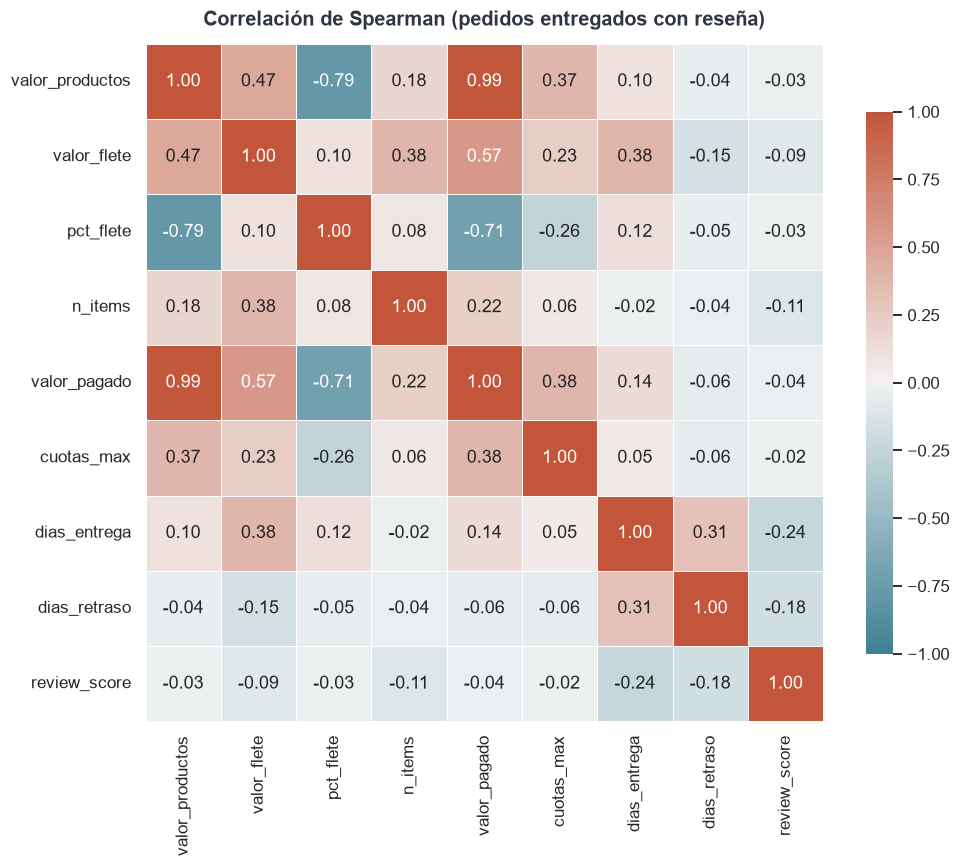

Correlación con review_score:
dias_entrega      -0.24
dias_retraso      -0.18
n_items           -0.11
valor_flete       -0.09
valor_pagado      -0.04
pct_flete         -0.03
valor_productos   -0.03
cuotas_max        -0.02


In [49]:
cols_corr = ["valor_productos", "valor_flete", "pct_flete", "n_items", "valor_pagado", "cuotas_max",
             "dias_entrega", "dias_retraso", "review_score"]
corr = ent_ok.dropna(subset=["review_score"])[cols_corr].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(220, 20, as_cmap=True), center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.6, linecolor="white", cbar_kws={"shrink": 0.8})
plt.title("Correlación de Spearman (pedidos entregados con reseña)")
plt.show()

print("Correlación con review_score:")
print(corr["review_score"].drop("review_score").sort_values(key=abs, ascending=False).round(3).to_string())

## 11. Respuestas a las preguntas de negocio
Las cifras se calculan a partir de los datos analizados en las secciones anteriores.

### 1. ¿Cómo evolucionan los pedidos y los ingresos?

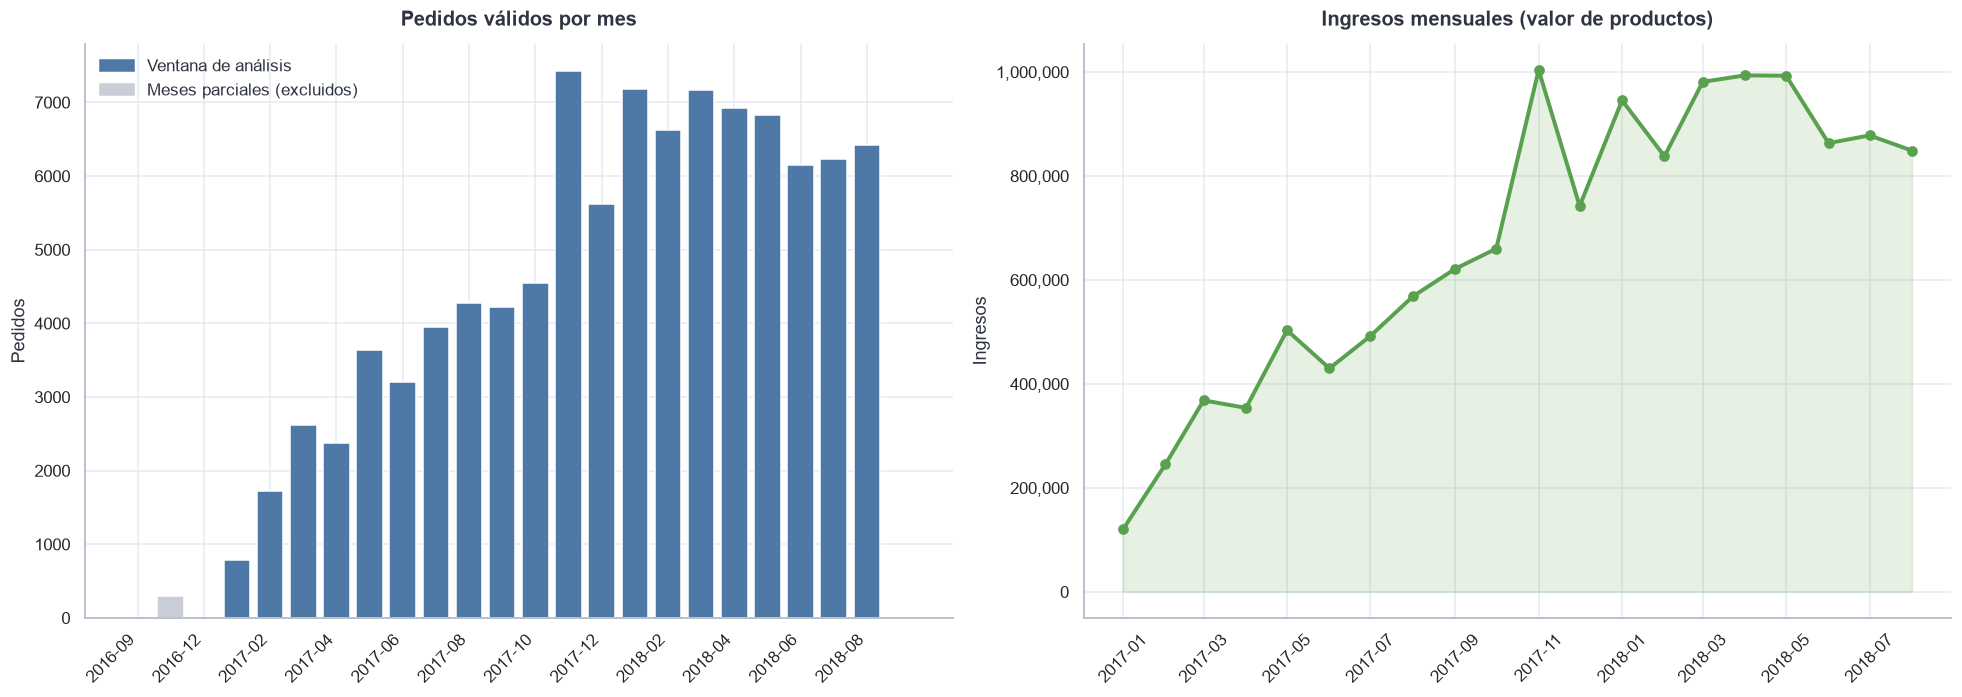

- La tendencia de pedidos es **creciente**: pasan de 787 a 6,421 mensuales entre 2017-01 y 2018-08 (+716%).
- Ingresos acumulados en la ventana: **13,449,530**, con ticket medio de **138.59**.
- El mes de mayores ingresos fue **2017-11** (1,003,862).
- La actividad se concentra los **lunes** y alrededor de las **16 h**.

In [50]:
etiquetas_mes = mensual_total["mes_compra"].dt.strftime("%Y-%m").tolist()
posiciones = np.arange(len(mensual_total))

fig, ax = plt.subplots(1, 2, figsize=(18, 6.5))
ax[0].bar(posiciones, mensual_total["pedidos"], color=np.where(mensual_total["en_ventana"], AZUL, GRIS), edgecolor="white")
ax[0].set_xticks(posiciones[::2])
ax[0].set_xticklabels(etiquetas_mes[::2], rotation=45, ha="right")
ax[0].set_title("Pedidos válidos por mes")
ax[0].set_ylabel("Pedidos")
ax[0].legend(handles=[Patch(color=AZUL, label="Ventana de análisis"), Patch(color=GRIS, label="Meses parciales (excluidos)")], frameon=False)

ax[1].plot(mensual["mes_compra"], mensual["ingresos"], color=VERDE, marker="o", lw=2.6)
ax[1].fill_between(mensual["mes_compra"], mensual["ingresos"], color=VERDE, alpha=0.15)
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax[1].tick_params(axis="x", rotation=45)
ax[1].yaxis.set_major_formatter(miles)
ax[1].set_title("Ingresos mensuales (valor de productos)")
ax[1].set_ylabel("Ingresos")
plt.tight_layout()
plt.show()

pico = mensual.loc[mensual["ingresos"].idxmax()]
tendencia = "creciente" if crec_total > 10 else ("decreciente" if crec_total < -10 else "estable")
dia_pico = por_dia.idxmax()
hora_pico = int(por_hora.idxmax())

mostrar([
    f"- La tendencia de pedidos es **{tendencia}**: pasan de {mensual['pedidos'].iloc[0]:,} a {mensual['pedidos'].iloc[-1]:,} "
    f"mensuales entre {mensual['mes_compra'].iloc[0]:%Y-%m} y {mensual['mes_compra'].iloc[-1]:%Y-%m} ({crec_total:+,.0f}%).",
    f"- Ingresos acumulados en la ventana: **{mensual['ingresos'].sum():,.0f}**, con ticket medio de **{mensual['ticket_medio'].mean():,.2f}**.",
    f"- El mes de mayores ingresos fue **{pico['mes_compra']:%Y-%m}** ({pico['ingresos']:,.0f}).",
    f"- La actividad se concentra los **{dia_pico}** y alrededor de las **{hora_pico} h**.",
])

### 2. ¿Dónde se concentran las ventas?

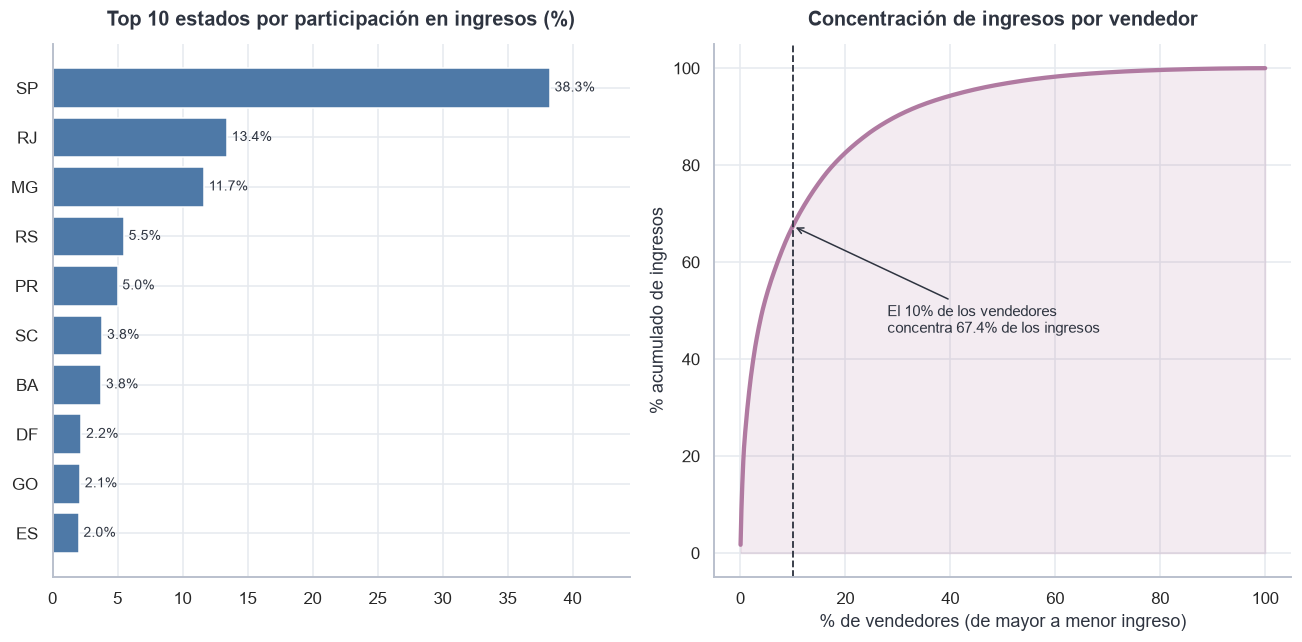

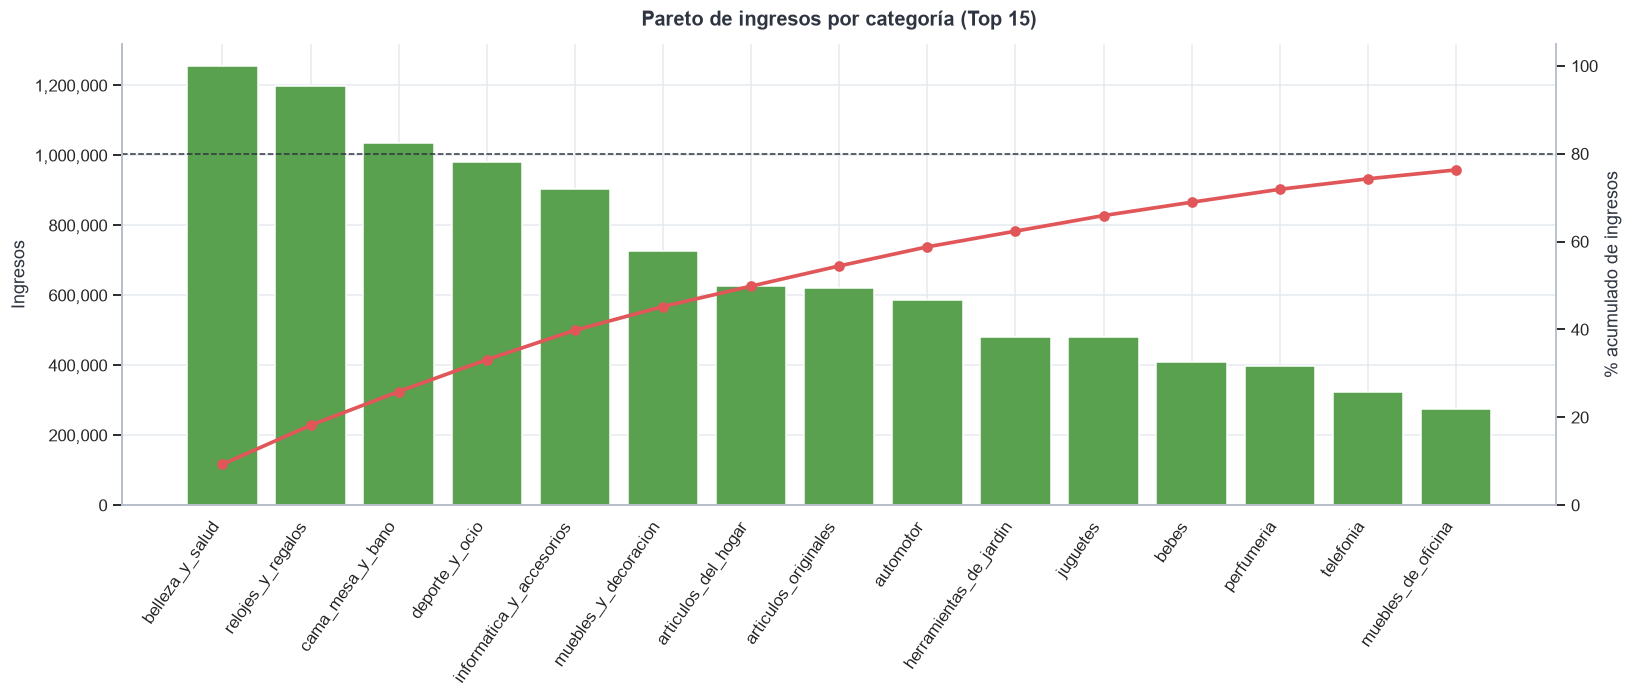

- **Geografía:** SP, RJ, MG concentran **63.4%** de los ingresos; SP lidera con 38.3%. La región **Sudeste** aporta 65.4%.
- **Categorías:** las tres principales (belleza_y_salud, relojes_y_regalos, cama_mesa_y_bano) suman **25.9%** de los ingresos; 18 de 74 categorías explican el 80%.
- **Vendedores:** el 10% de los vendedores concentra el **67.4%** de los ingresos (sobre 3,053 vendedores activos).

In [60]:
x_vend= np.arange(1, len(vend) + 1) / len(vend) * 100
top_estados = geo["% ingresos"].head(10)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
barras(ax[0], top_estados, AZUL, "Top 10 estados por participación en ingresos (%)", horizontal=True, fmt="{:.1f}%")
ax[1].plot(x_vend, acum.values, color=VIOLETA, lw=2.8)
ax[1].fill_between(x_vend, acum.values, color=VIOLETA, alpha=0.15)
ax[1].axvline(10, color=OSCURO, ls="--", lw=1.2)
ax[1].annotate(f"El 10% de los vendedores\nconcentra {share_top10:.1f}% de los ingresos", xy=(10, share_top10),
               xytext=(28, share_top10 - 22), arrowprops=dict(arrowstyle="->", color=OSCURO), fontsize=10)
ax[1].set_xlabel("% de vendedores (de mayor a menor ingreso)")
ax[1].set_ylabel("% acumulado de ingresos")
ax[1].set_title("Concentración de ingresos por vendedor")
plt.tight_layout()
plt.show()

top = cat.head(15)
fig, ax = plt.subplots(figsize=(15, 6.5))
ax.bar(top.index, top["ingresos"], color=VERDE, edgecolor="white")
ax.yaxis.set_major_formatter(miles)
ax.set_ylabel("Ingresos")
ax.tick_params(axis="x", rotation=55)
plt.setp(ax.get_xticklabels(), ha="right")
ax2 = ax.twinx()
ax2.plot(top.index, top["% acumulado"], color=ROJO, marker="o", lw=2.4)
ax2.axhline(80, color=OSCURO, ls="--", lw=1)
ax2.set_ylim(0, 105)
ax2.set_ylabel("% acumulado de ingresos")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title("Pareto de ingresos por categoría (Top 15)")
plt.tight_layout()
plt.show()

top3_estados = geo.head(3)
top3_cat = cat.head(3)
mostrar([
    f"- **Geografía:** {', '.join(top3_estados.index)} concentran **{top3_estados['% ingresos'].sum():.1f}%** de los ingresos; "
    f"{geo.index[0]} lidera con {geo['% ingresos'].iloc[0]:.1f}%. La región **{region.index[0]}** aporta {region['% ingresos'].iloc[0]:.1f}%.",
    f"- **Categorías:** las tres principales ({', '.join(top3_cat.index)}) suman **{top3_cat['% ingresos'].sum():.1f}%** de los ingresos; "
    f"{n80} de {len(cat)} categorías explican el 80%.",
    f"- **Vendedores:** el 10% de los vendedores concentra el **{share_top10:.1f}%** de los ingresos (sobre {len(vend):,} vendedores activos).",
])

### 3. ¿Cómo pagan los clientes?

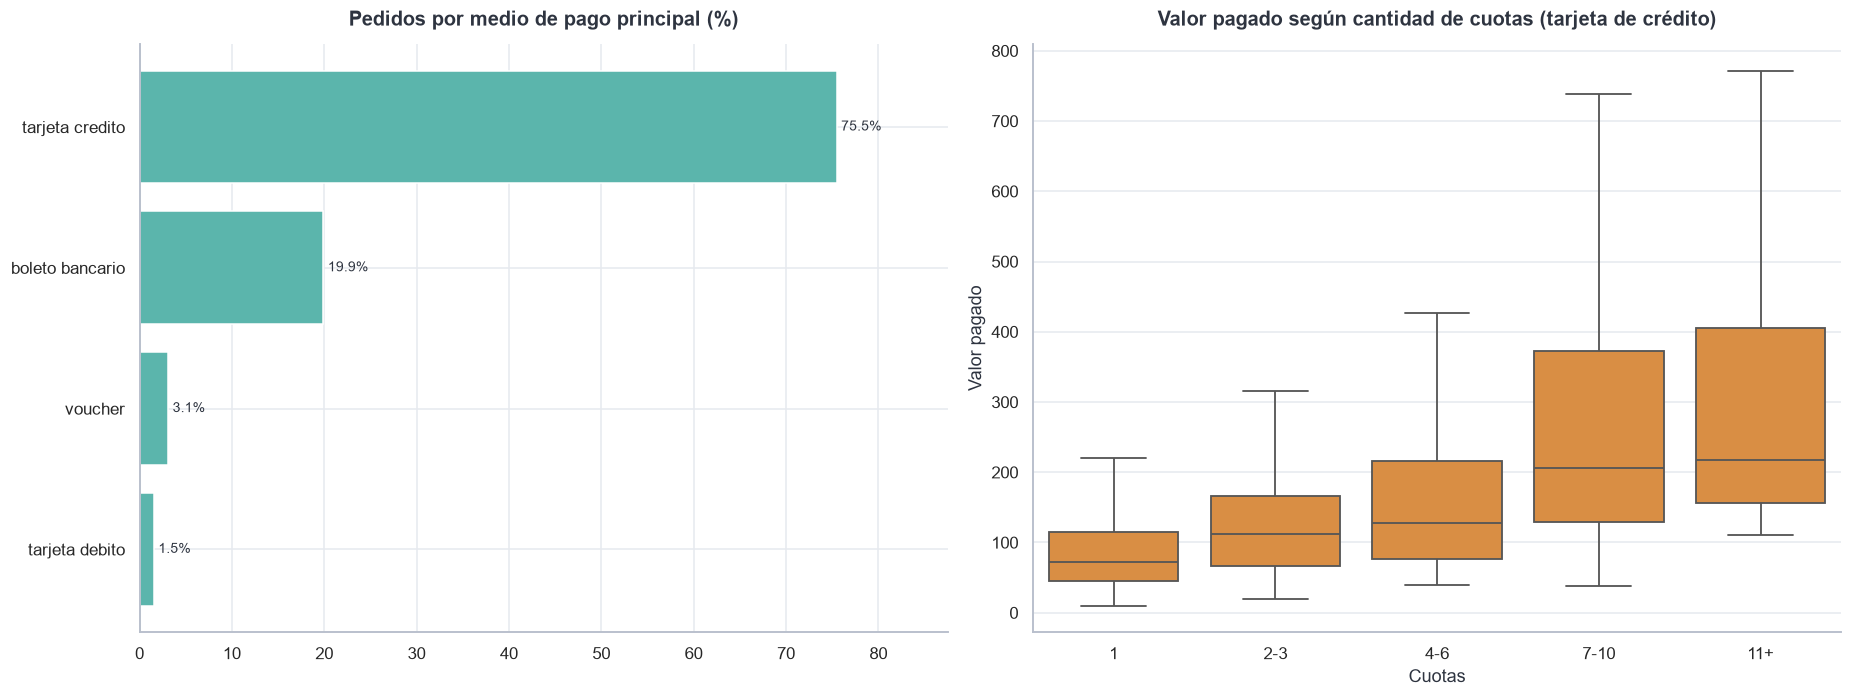

- El medio principal es **tarjeta credito** (75.5% de los pedidos); la tarjeta de crédito concentra 75.5% de los pedidos.
- Entre quienes pagan con tarjeta, **68.0%** financia en más de una cuota (promedio 3.6).
- La mediana pagada crece con las cuotas: 71.63 en 1 cuota vs 217.10 en el tramo 11+.

In [61]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
barras(ax[0], pagos_res["% pedidos"].rename(lambda s: s.replace("_", " ")), TURQUESA, "Pedidos por medio de pago principal (%)",
       horizontal=True, fmt="{:.1f}%")
sns.boxplot(data=tarjeta, x="tramo_cuotas", y="valor_pagado", color=NARANJA, showfliers=False, linewidth=1.2, ax=ax[1])
ax[1].yaxis.set_major_formatter(miles)
ax[1].set_title("Valor pagado según cantidad de cuotas (tarjeta de crédito)")
ax[1].set_xlabel("Cuotas")
ax[1].set_ylabel("Valor pagado")
plt.tight_layout()
plt.show()

pct_tarjeta = master_v["payment_type_principal"].eq("credit_card").mean() * 100
pct_cuotas = (tarjeta["cuotas_max"] > 1).mean() * 100
cuotas_media = tarjeta["cuotas_max"].mean()
relacion = "crece" if med_cuotas.iloc[-1] > med_cuotas.iloc[0] else "no crece"

mostrar([
    f"- El medio principal es **{pagos_res.index[0].replace('_', ' ')}** ({pagos_res['% pedidos'].iloc[0]:.1f}% de los pedidos); "
    f"la tarjeta de crédito concentra {pct_tarjeta:.1f}% de los pedidos.",
    f"- Entre quienes pagan con tarjeta, **{pct_cuotas:.1f}%** financia en más de una cuota (promedio {cuotas_media:.1f}).",
    f"- La mediana pagada {relacion} con las cuotas: {med_cuotas.iloc[0]:,.2f} en {med_cuotas.index[0]} cuota vs {med_cuotas.iloc[-1]:,.2f} en el tramo {med_cuotas.index[-1]}.",
])

### 4. ¿Qué tan bien funciona la logística?

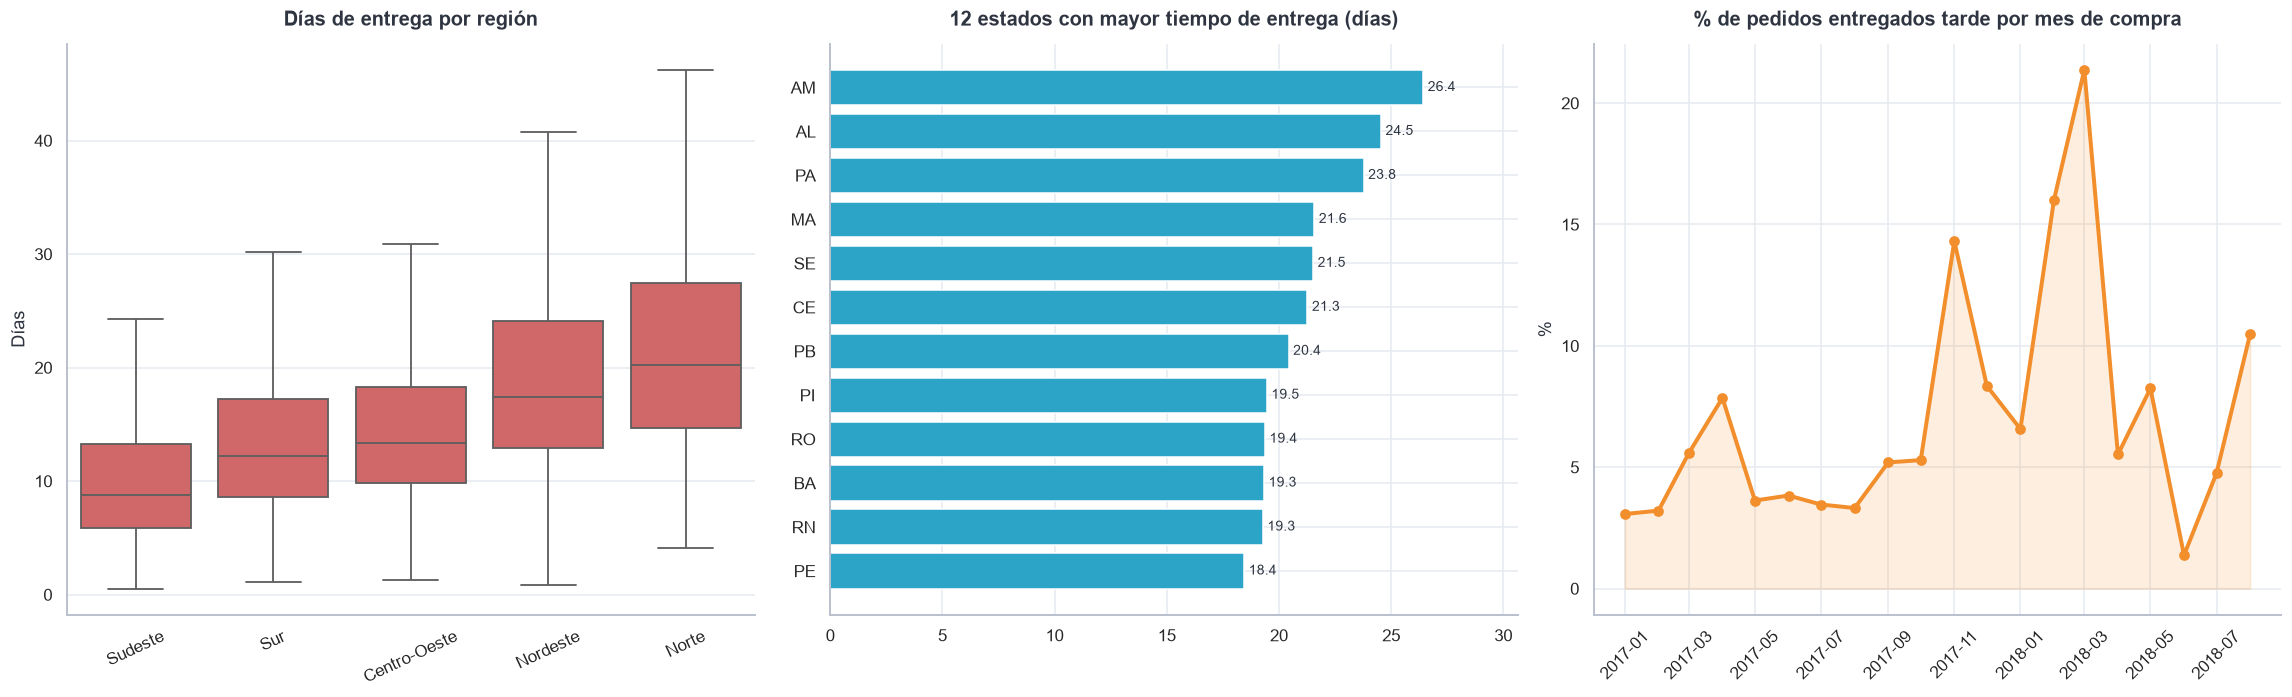

- Mediana de entrega: **10.3 días**; el 90% de los pedidos llega en 23.2 días o menos.
- **8.2%** de los pedidos llega después de la fecha estimada.
- Por región, la entrega más lenta es **Norte** (22.6 días) y la más rápida **Sudeste** (10.8 días).
- Entre estados con al menos 100 pedidos, el más lento es **AM** (26.4 días) y el de mayor flete medio, **PB** (48.30).

In [62]:
MIN_PEDIDOS_ESTADO = 100
geo_ok = geo[geo["pedidos"] >= MIN_PEDIDOS_ESTADO]
region_lenta, region_rapida = region["dias_entrega"].idxmax(), region["dias_entrega"].idxmin()
orden_reg = ent_ok.groupby("customer_region")["dias_entrega"].median().sort_values().index

fig, ax = plt.subplots(1, 3, figsize=(21, 6.5))
sns.boxplot(data=ent_ok, x="customer_region", y="dias_entrega", order=orden_reg, color=ROJO, showfliers=False, linewidth=1.2, ax=ax[0])
ax[0].set_title("Días de entrega por región")
ax[0].set_xlabel("")
ax[0].set_ylabel("Días")
ax[0].tick_params(axis="x", rotation=25)
barras(ax[1], geo_ok["dias_entrega"].sort_values(ascending=False).head(12), CIAN, "12 estados con mayor tiempo de entrega (días)",
       horizontal=True, fmt="{:.1f}")
ax[2].plot(tarde_mes.index, tarde_mes.values, color=NARANJA, marker="o", lw=2.6)
ax[2].fill_between(tarde_mes.index, tarde_mes.values, color=NARANJA, alpha=0.15)
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax[2].tick_params(axis="x", rotation=45)
ax[2].set_title("% de pedidos entregados tarde por mes de compra")
ax[2].set_ylabel("%")
plt.tight_layout()
plt.show()

mostrar([
    f"- Mediana de entrega: **{ent_ok['dias_entrega'].median():.1f} días**; el 90% de los pedidos llega en {ent_ok['dias_entrega'].quantile(0.9):.1f} días o menos.",
    f"- **{ent_ok['entregado_tarde'].mean() * 100:.1f}%** de los pedidos llega después de la fecha estimada.",
    f"- Por región, la entrega más lenta es **{region_lenta}** ({region.loc[region_lenta, 'dias_entrega']:.1f} días) y la más rápida **{region_rapida}** "
    f"({region.loc[region_rapida, 'dias_entrega']:.1f} días).",
    f"- Entre estados con al menos {MIN_PEDIDOS_ESTADO} pedidos, el más lento es **{geo_ok['dias_entrega'].idxmax()}** "
    f"({geo_ok['dias_entrega'].max():.1f} días) y el de mayor flete medio, **{geo_ok['flete_medio'].idxmax()}** ({geo_ok['flete_medio'].max():,.2f}).",
])

### 5. ¿Qué factores se asocian a la satisfacción?

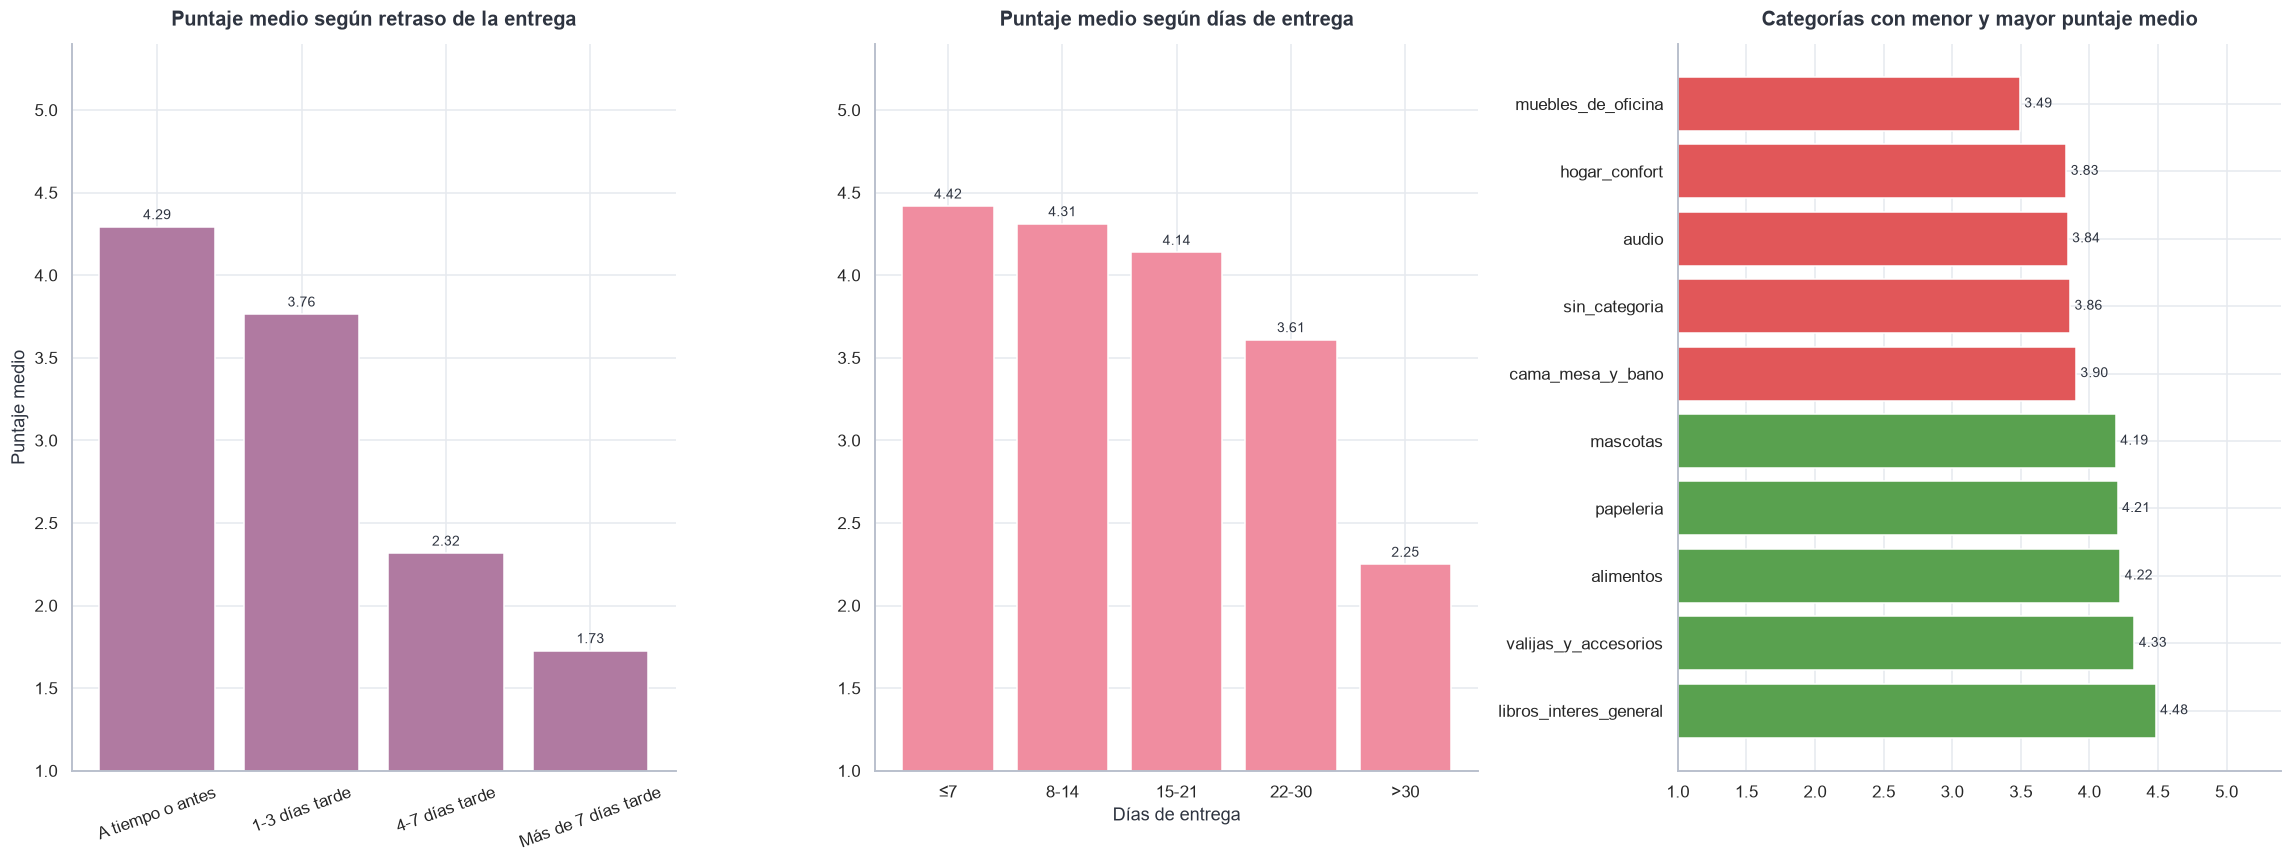

- Puntaje medio: **4.15**; 21.1% de las reseñas indica insatisfacción.
- El **retraso en la entrega** es el factor más visible: el puntaje pasa de **4.29** (a tiempo) a **1.73** (más de 7 días tarde).
- Correlación de Spearman con el puntaje: días de retraso **-0.18**, días de entrega **-0.24**.
- Categorías con menor puntaje: **muebles_de_oficina** (3.49) y **hogar_confort** (3.83); con mayor puntaje: **libros_interes_general** (4.48).
- Son asociaciones observadas, no relaciones causales.

In [63]:
corr_retraso = corr.loc["dias_retraso", "review_score"]
corr_entrega = corr.loc["dias_entrega", "review_score"]
a_tiempo, muy_tarde = tabla_retraso["puntaje_medio"].iloc[0], tabla_retraso["puntaje_medio"].iloc[-1]

hay_categorias = len(cat_score) >= 4
fig, ax = plt.subplots(1, 3 if hay_categorias else 2, figsize=(21 if hay_categorias else 15, 8))
barras(ax[0], tabla_retraso["puntaje_medio"], VIOLETA, "Puntaje medio según retraso de la entrega", fmt="{:.2f}", ylabel="Puntaje medio")
ax[0].set_ylim(1, 5.4)
ax[0].tick_params(axis="x", rotation=20)
barras(ax[1], puntaje_por_entrega, ROSA, "Puntaje medio según días de entrega", fmt="{:.2f}", xlabel="Días de entrega")
ax[1].set_ylim(1, 5.4)
if hay_categorias:
    extremos = pd.concat([cat_score.head(5), cat_score.tail(5)])["score_medio"]
    extremos = extremos[~extremos.index.duplicated()]
    colores_cat = np.where(extremos.values < cat_score["score_medio"].median(), ROJO, VERDE)
    barras(ax[2], extremos, list(colores_cat), "Categorías con menor y mayor puntaje medio", horizontal=True, fmt="{:.2f}")
    ax[2].set_xlim(1, 5.4)
plt.tight_layout()
plt.show()

lineas = [
    f"- Puntaje medio: **{ent_rev['review_score'].mean():.2f}**; {ent_rev['insatisfecho'].mean() * 100:.1f}% de las reseñas indica insatisfacción.",
    f"- {'El **retraso en la entrega** es el factor más visible: el' if corr_retraso < -0.1 else 'Según el retraso en la entrega, el'} puntaje pasa de **{a_tiempo:.2f}** (a tiempo) a **{muy_tarde:.2f}** (más de 7 días tarde).",
    f"- Correlación de Spearman con el puntaje: días de retraso **{corr_retraso:.2f}**, días de entrega **{corr_entrega:.2f}**.",
]
if len(cat_score) > 1:
    lineas.append(f"- Categorías con menor puntaje: **{cat_score.index[0]}** ({cat_score['score_medio'].iloc[0]:.2f}) y **{cat_score.index[1]}** "
                  f"({cat_score['score_medio'].iloc[1]:.2f}); con mayor puntaje: **{cat_score.index[-1]}** ({cat_score['score_medio'].iloc[-1]:.2f}).")
lineas.append("- Son asociaciones observadas, no relaciones causales.")
mostrar(lineas)

### 6. ¿Qué tan recurrentes son los clientes?

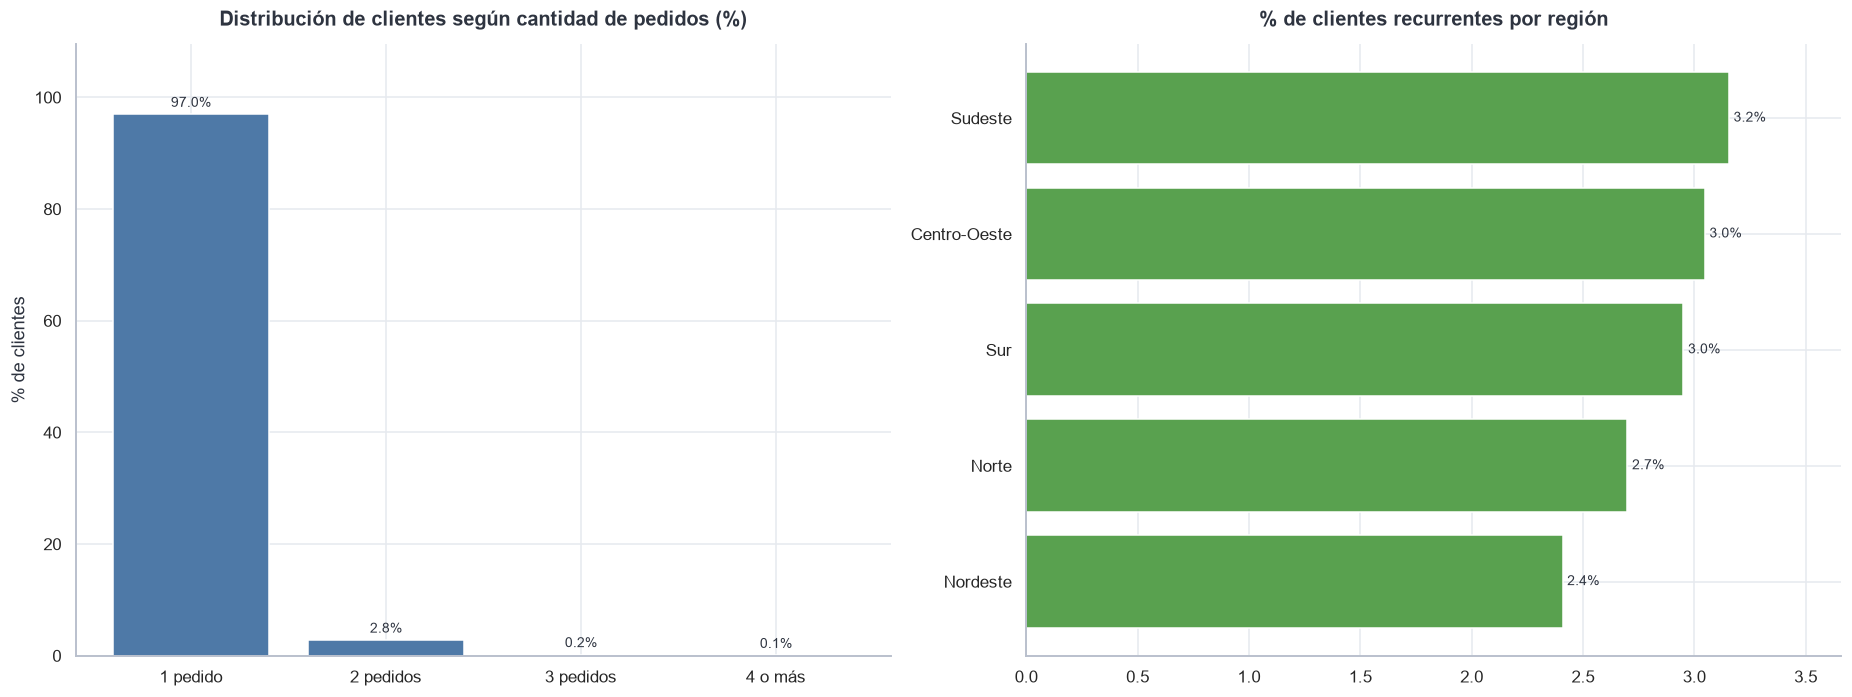

- Sobre **94,990** clientes únicos, **3.0%** compró más de una vez.
- Promedio de **1.03** pedidos por cliente. La base es mayoritariamente de compra única.

In [64]:
etiquetas_ped = {1: "1 pedido", 2: "2 pedidos", 3: "3 pedidos", 4: "4 o más"}
dist_pct = ped_por_persona.clip(upper=4).value_counts(normalize=True).sort_index().mul(100)
dist_pct.index = [etiquetas_ped[i] for i in dist_pct.index]

fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
barras(ax[0], dist_pct, AZUL, "Distribución de clientes según cantidad de pedidos (%)", fmt="{:.1f}%", ylabel="% de clientes")
barras(ax[1], rec_region, VERDE, "% de clientes recurrentes por región", horizontal=True, fmt="{:.1f}%")
plt.tight_layout()
plt.show()

perfil = ("La base es mayoritariamente de compra única." if pct_repite < 10
          else "La base incluye un grupo relevante de clientes recurrentes.")
mostrar([
    f"- Sobre **{len(ped_por_persona):,}** clientes únicos, **{pct_repite:.1f}%** compró más de una vez.",
    f"- Promedio de **{ped_por_persona.mean():.2f}** pedidos por cliente. {perfil}",
])

### Limitaciones
- Las reseñas representan solo a los clientes que decidieron opinar.
- La ventana temporal disponible no permite confirmar estacionalidad anual.
- Los montos están en la moneda original, sin ajuste por inflación.


## 12. Bitácora de decisiones y exportación

In [65]:
OUT_DIR = DATA_DIR / "limpio"
OUT_DIR.mkdir(exist_ok=True)

for nombre, df in clean.items():
    df.to_csv(OUT_DIR / f"{nombre}_limpio.csv", index=False, encoding="utf-8")

master.to_csv(OUT_DIR / "master_pedidos.csv", index=False, encoding="utf-8")
items_full.to_csv(OUT_DIR / "master_items.csv", index=False, encoding="utf-8")

for archivo in sorted(OUT_DIR.glob("*.csv")):
    print(f"{archivo.name:<28} {archivo.stat().st_size / 1e6:>7.1f} MB")

customers_limpio.csv            10.7 MB
items_limpio.csv                18.0 MB
master_items.csv                35.7 MB
master_pedidos.csv              45.3 MB
orders_limpio.csv               26.8 MB
payments_limpio.csv              8.0 MB
products_limpio.csv              4.0 MB
reviews_limpio.csv              14.9 MB
